In [ ]:
!pip install --upgrade numpy pmdarima xgboost optuna -q

In [ ]:
# Configure environment
import os
os.environ["TF_XLA_FLAGS"] = "--tf_xla_enable_xla_devices=false"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import re

# Machine Learning libraries
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                           r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Time series and deep learning
from statsmodels.tsa.statespace.sarimax import SARIMAX
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# XGBoost and optimization
import xgboost as xgb
import optuna

# Other utilities
from pandas.tseries.frequencies import to_offset

# Set global configurations
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
optuna.logging.set_verbosity(optuna.logging.WARNING)  # Reduce optuna output

In [ ]:
# ================================
# UTILITY FUNCTIONS
# ================================

def load_and_preprocess_data(file_path):
    """Load and preprocess the groundwater data"""
    df = pd.read_excel(file_path)
    df.rename(columns=lambda c: c.strip(), inplace=True)
    df['Date'] = pd.to_datetime(df['Date'])
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)
    df = df.dropna(axis=0)
    return df

def nse(y_true, y_pred):
    return 1 - (np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))

def calculate_metrics(y_true, y_pred):
    """Calculate comprehensive performance metrics"""
    return {
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'R²': r2_score(y_true, y_pred),
        'MAPE': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'NSE': nse(y_true, y_pred)
    }

def print_metrics(metrics, model_name):
    """Print formatted metrics"""
    print(f"\n📊 {model_name} Model Performance Metrics")
    print("-" * 40)
    for metric, value in metrics.items():
        print(f"{metric:<6}: {value:.4f}")

def create_forecast_plots(df, actual_col, predicted_col, forecast_col,
                         model_name, years_to_plot=5):
    """Create standardized forecast plots"""

    # Full time series plot
    plt.figure(figsize=(15, 8))
    plt.plot(df["Date"], df[actual_col], label="Actual GWL",
             linewidth=2, color='blue')
    plt.plot(df["Date"], df[predicted_col], "--", label="Predicted GWL",
             linewidth=2, color='green')
    plt.plot(df["Date"], df[forecast_col], ":", label="Forecast (52 weeks)",
             linewidth=2, color="red")

    plt.title(f"{model_name}: Groundwater Level Prediction and Forecast (Original Scale)",
              fontsize=16)
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("GWL (m)", fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Recent years plot
    plt.figure(figsize=(15, 8))
    start_date_filter = df["Date"].iloc[-52*years_to_plot-52]
    filtered_data = df[df["Date"] >= start_date_filter]

    plt.plot(filtered_data["Date"], filtered_data[actual_col],
             label="Actual GWL", linewidth=2, color='blue')
    plt.plot(filtered_data["Date"], filtered_data[predicted_col], "--",
             label="Predicted GWL", linewidth=2, color='green')
    plt.plot(filtered_data["Date"], filtered_data[forecast_col], ":",
             label="Forecast (52 weeks)", linewidth=2, color="red")

    plt.title(f"{model_name}: Last {years_to_plot} Years + Forecast (Original Scale)",
              fontsize=16)
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("GWL (m)", fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def add_lag_features(df, target_col="GWL (m)", rainfall_col="Rainfall (mm)"):
    """Add lag features and seasonality components"""
    df = df.copy()

    # Add lag features
    for lag in (1, 2, 3):
        df[f"GWL_lag{lag}"] = df[target_col].shift(lag)
    df["Rainfall_lag1"] = df[rainfall_col].shift(1)

    # Add seasonal features
    df["month"] = df.index.month
    df["sin_m"] = np.sin(2 * np.pi * df["month"] / 12)
    df["cos_m"] = np.cos(2 * np.pi * df["month"] / 12)

    return df.dropna()

def export_results(df, filename, output_dir):
    """Export results to Excel with proper formatting"""
    filepath = os.path.join(output_dir, filename)
    df.to_excel(filepath, index_label="Date")
    print(f"📁 Results exported to: {filename}")
    print(f"   Rows: {len(df)}, Columns: {len(df.columns)}")
    return filepath

print("✅ Utility functions loaded successfully!")

✅ Utility functions loaded successfully!


# 1. Data Loading and Configuration

Loading the groundwater data and setting up the workspace configuration.

In [ ]:
# Configuration
FILE = "Thesis 19 for barisal.xlsx"
OUTPUT_DIR = "Barisal Sadar"
FORECAST_WEEKS = 52

# Create output directory
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load and preprocess data
df_original = load_and_preprocess_data(FILE)

print(f"📊 Data loaded successfully!")
print(f"   Shape: {df_original.shape}")
print(f"   Date range: {df_original.index.min()} to {df_original.index.max()}")
print(f"   Features: {list(df_original.columns)}")

# Create scaled version for models that need it
numeric_cols = df_original.select_dtypes(include=[np.number]).columns
scaler = StandardScaler()
df_scaled = df_original.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df_original[numeric_cols])

print(f"✅ Data preprocessing completed!")
print(f"   Features available: {len(numeric_cols)}")
print(f"   Target variable: GWL (m)")

df_original.head()

📊 Data loaded successfully!
   Shape: (351, 8)
   Date range: 1996-01-01 00:00:00 to 2025-03-01 00:00:00
   Features: ['GWL (m)', 'Temperature max (°C)', 'Temperature min (°C)', 'Humidity (%)', 'Rainfall (mm)', 'Soil Moisture (kg/m^2)', 'Evapotranspiration (mm/day)', 'Wind Speed (m/s)']
✅ Data preprocessing completed!
   Features available: 8
   Target variable: GWL (m)


,GWL (m),Temperature max (°C),Temperature min (°C),Humidity (%),Rainfall (mm),Soil Moisture (kg/m^2),Evapotranspiration (mm/day),Wind Speed (m/s)
Date,,,,,,,,
1996-01-01,1.377662,25.76,12.38,79.65,0,263.1835,0.6907,0.25
1996-02-01,1.395896,29.16,15.01,75.69,20,296.0756,1.3599,0.38
1996-03-01,1.414371,33.11,22.26,77.16,12,280.5961,1.2164,1.22
1996-04-01,1.433091,34.13,23.48,81.67,131,274.6669,2.2411,1.16
1996-05-01,1.452058,34.31,25.32,84.26,94,288.9069,2.3573,2.33


# 2. SARIMA Model

**Seasonal Autoregressive Integrated Moving Average (SARIMA)**
- Captures trend, seasonality, and noise in time series data
- Parameters: (1,1,1)(1,1,1,12) for AR, differencing, MA, and seasonal components
- Generates 52-week forecasts using fitted model

🔄 Training SARIMA models...
   Using data shape: (351, 8)
   Features: ['GWL (m)', 'Temperature max (°C)', 'Temperature min (°C)', 'Humidity (%)', 'Rainfall (mm)', 'Soil Moisture (kg/m^2)', 'Evapotranspiration (mm/day)', 'Wind Speed (m/s)']
🔄 Training SARIMA models...
Training SARIMA for GWL (m)...


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


✅ SARIMA for GWL (m) trained successfully
Training SARIMA for Temperature max (°C)...


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


✅ SARIMA for Temperature max (°C) trained successfully
Training SARIMA for Temperature min (°C)...


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (7 outputs left out)

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


✅ SARIMA for Evapotranspiration (mm/day) trained successfully
Training SARIMA for Wind Speed (m/s)...


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


✅ SARIMA for Wind Speed (m/s) trained successfully
✅ SARIMA forecasting completed and inverse transformed to original scale!

🔄 Generating predictions and forecasts...

📊 SARIMA Model Performance Metrics
----------------------------------------
RMSE  : 0.2022
MAE   : 0.1394
MSE   : 0.0409
R²    : 0.7858
MAPE  : 9.6236
NSE   : 0.7858


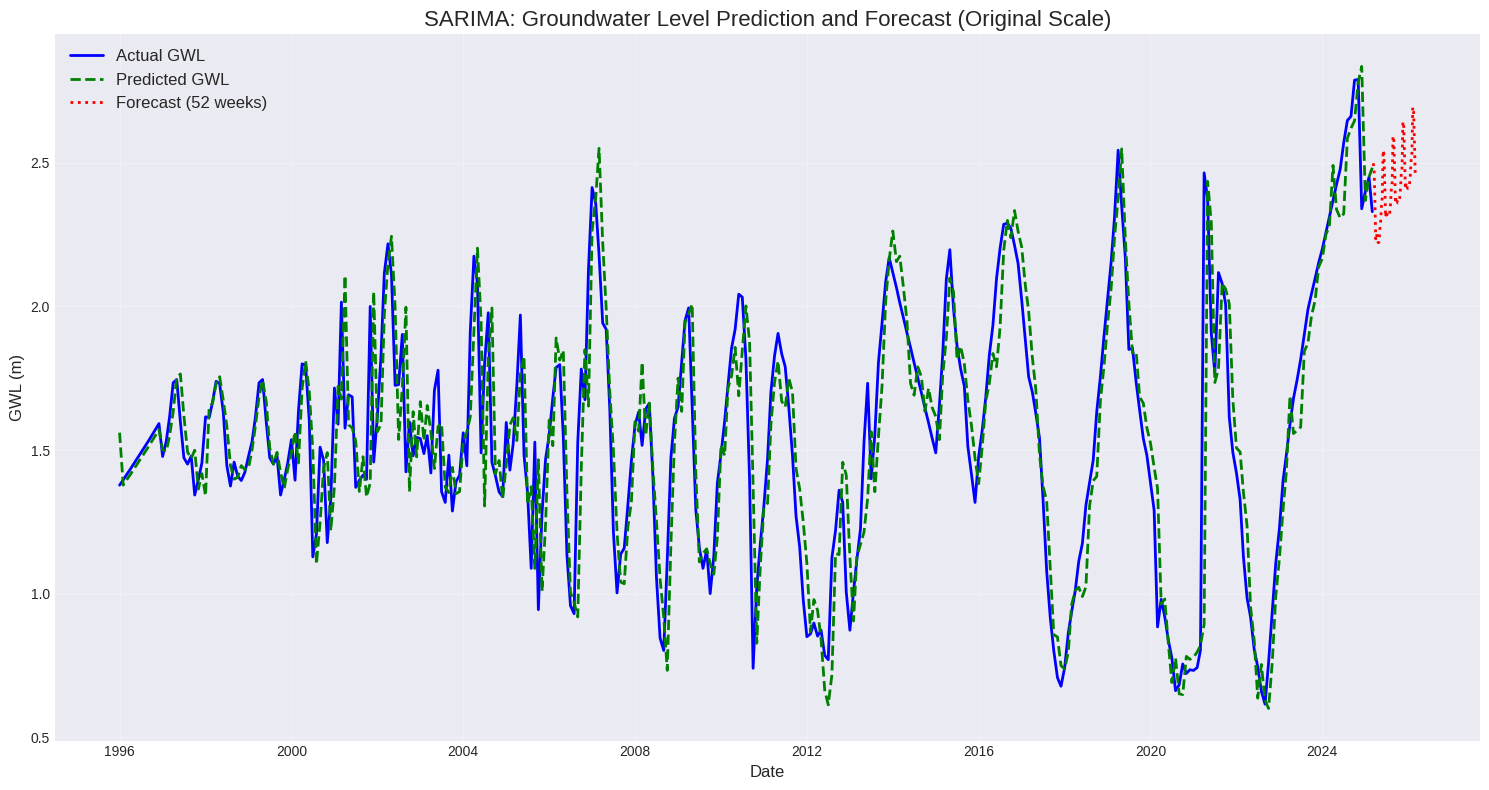

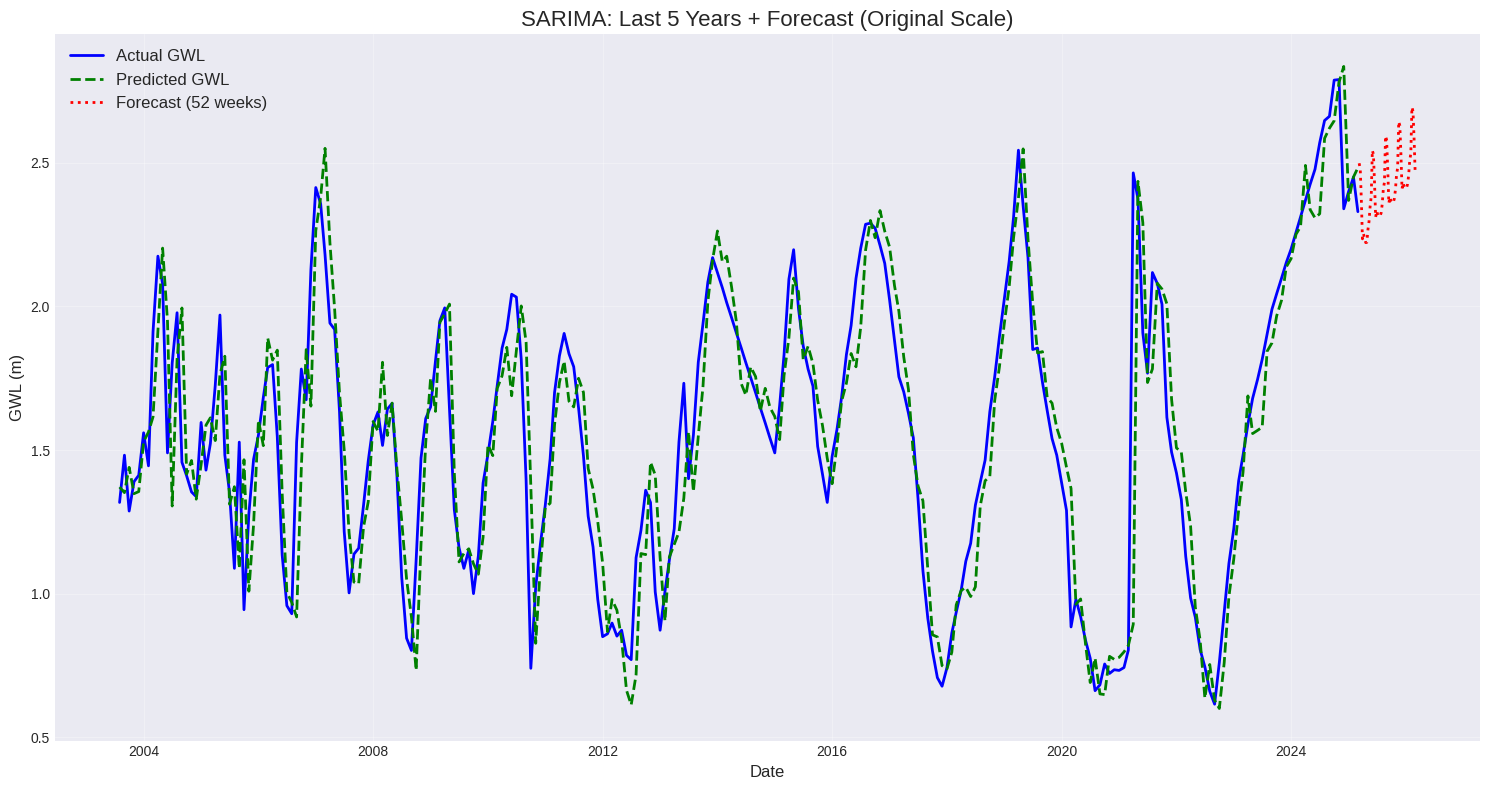

📁 Results exported to: GWL_SARIMA_1996_2026.xlsx
   Rows: 403, Columns: 4
✅ SARIMA model completed successfully!


In [ ]:
# Use the existing scaled data from the data loading section
# (This uses StandardScaler which was already fitted)

print("🔄 Training SARIMA models...")
print(f"   Using data shape: {df_scaled.shape}")
print(f"   Features: {list(numeric_cols)}")

print("🔄 Training SARIMA models...")

# Use the existing scaled data from the data loading section
# (This uses StandardScaler which was already fitted in the data loading section)

# Train SARIMA models for each feature
sarima_models = {}
sarima_forecasts = {}

for feature in numeric_cols:
    print(f"Training SARIMA for {feature}...")

    # Use the scaled data for training
    scaled_series = df_scaled[feature]

    # Fit SARIMA model
    model = SARIMAX(scaled_series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
    fitted_model = model.fit(disp=False)

    # Make forecast
    forecast_scaled = fitted_model.forecast(steps=FORECAST_WEEKS)

    # Store model and forecast
    sarima_models[feature] = fitted_model
    sarima_forecasts[feature] = forecast_scaled

    print(f"✅ SARIMA for {feature} trained successfully")

# Inverse transform all forecasts to original scale
def inverse_transform_sarima(forecasts_dict, scaler, numeric_cols):
    """
    Inverse transform SARIMA forecasts from scaled to original scale.
    Uses the StandardScaler that was fitted on the original data.
    """
    # Create array with zeros for all features
    n_features = len(numeric_cols)
    n_forecast_steps = len(list(forecasts_dict.values())[0])

    # Create a matrix to hold all forecasts
    forecasts_matrix = np.zeros((n_forecast_steps, n_features))

    # Fill in the forecasts for each feature
    for i, feature in enumerate(numeric_cols):
        forecasts_matrix[:, i] = forecasts_dict[feature]

    # Inverse transform using the scaler
    forecasts_original = scaler.inverse_transform(forecasts_matrix)

    # Convert back to dictionary format
    forecasts_original_dict = {}
    for i, feature in enumerate(numeric_cols):
        forecasts_original_dict[feature] = forecasts_original[:, i]

    return forecasts_original_dict

# Convert forecasts to original scale
sarima_forecasts_original = inverse_transform_sarima(sarima_forecasts, scaler, numeric_cols)

print("✅ SARIMA forecasting completed and inverse transformed to original scale!")

# Generate predictions and forecasts for GWL
print("\n🔄 Generating predictions and forecasts...")

gwl_model = sarima_models['GWL (m)']
gwl_actual_scaled = df_scaled['GWL (m)']

# In-sample fitted values and out-of-sample forecast (scaled)
gwl_fitted_scaled = gwl_model.predict(start=gwl_actual_scaled.index[0],
                                      end=gwl_actual_scaled.index[-1])
gwl_forecast_scaled = gwl_model.forecast(steps=FORECAST_WEEKS)

# Create future dates
future_dates = pd.date_range(start=gwl_actual_scaled.index[-1] + pd.Timedelta(weeks=1),
                            periods=FORECAST_WEEKS, freq="W")
gwl_forecast_scaled.index = future_dates

# Inverse transform to original scale using StandardScaler
gwl_col_idx = list(numeric_cols).index("GWL (m)")

def inverse_transform_gwl(series):
    """Inverse transform GWL values to original scale using StandardScaler"""
    if series is None or len(series) == 0:
        return series
    arr = series.values.reshape(-1, 1)
    # For StandardScaler: original = scaled * scale + mean
    return (arr * scaler.scale_[gwl_col_idx] + scaler.mean_[gwl_col_idx]).ravel()

# Convert to original scale
gwl_actual_orig = df_original['GWL (m)'].values
gwl_fitted_orig = inverse_transform_gwl(gwl_fitted_scaled)
gwl_forecast_orig = inverse_transform_gwl(gwl_forecast_scaled)

# Create export DataFrame
all_dates = gwl_actual_scaled.index.union(future_dates)
export_df_sarima = pd.DataFrame(index=all_dates)
export_df_sarima["Actual_GWL"] = pd.Series(gwl_actual_orig, index=gwl_actual_scaled.index)
export_df_sarima["Predicted_GWL"] = pd.Series(gwl_fitted_orig, index=gwl_fitted_scaled.index)
export_df_sarima["Forecast_GWL"] = pd.Series(gwl_forecast_orig, index=future_dates)
export_df_sarima.reset_index(inplace=True)
export_df_sarima.rename(columns={'index': 'Date'}, inplace=True)

# Calculate and print metrics
actual_for_metrics = gwl_actual_orig
predicted_for_metrics = gwl_fitted_orig
metrics_sarima = calculate_metrics(actual_for_metrics, predicted_for_metrics)
print_metrics(metrics_sarima, "SARIMA")

# Create visualizations
create_forecast_plots(export_df_sarima, "Actual_GWL", "Predicted_GWL",
                     "Forecast_GWL", "SARIMA")

# Export results
export_results(export_df_sarima, "GWL_SARIMA_1996_2026.xlsx", OUTPUT_DIR)

print("✅ SARIMA model completed successfully!")

# 2.1 SARIMA - All Features Analysis

Extended SARIMA analysis including all features and comprehensive metrics.

🔄 Generating comprehensive SARIMA analysis...


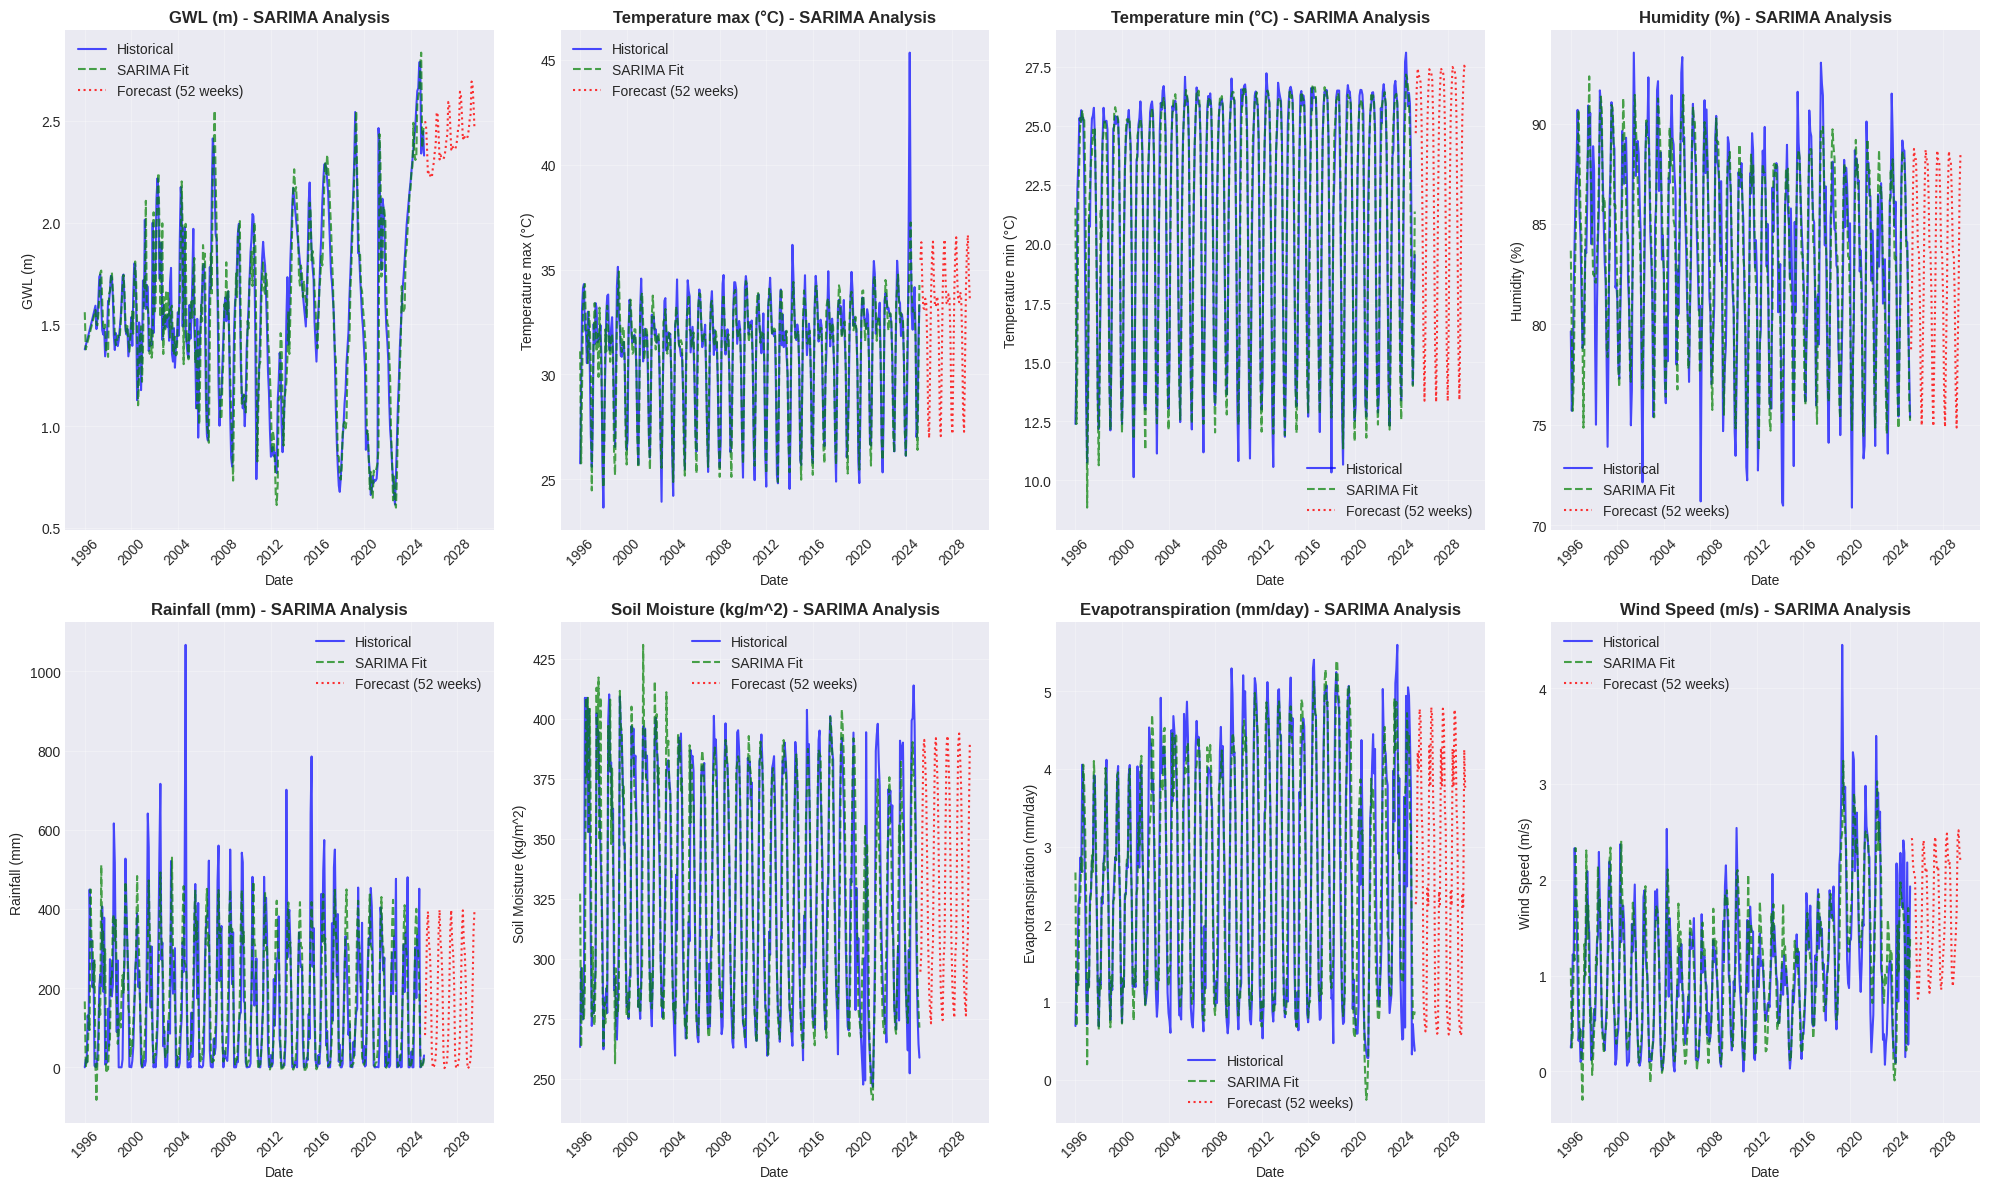


📊 SARIMA Model Summary Statistics

GWL (m):
  RMSE: 0.2022
  MAE:  0.1394
  R²:   0.7858

Temperature max (°C):
  RMSE: 1.1008
  MAE:  0.7283
  R²:   0.8461

Temperature min (°C):
  RMSE: 1.2062
  MAE:  0.7754
  R²:   0.9432

Humidity (%):
  RMSE: 2.2678
  MAE:  1.7537
  R²:   0.7964

Rainfall (mm):
  RMSE: 119.0469
  MAE:  79.6064
  R²:   0.5620

Soil Moisture (kg/m^2):
  RMSE: 22.5462
  MAE:  14.9627
  R²:   0.7826

Evapotranspiration (mm/day):
  RMSE: 0.6335
  MAE:  0.4320
  R²:   0.8283

Wind Speed (m/s):
  RMSE: 0.4135
  MAE:  0.2927
  R²:   0.6896

✅ Comprehensive SARIMA analysis completed!


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
import numpy as np

print("🔄 Generating comprehensive SARIMA analysis...")

# Create comprehensive predictions for all features
past_predictions = {}
future_predictions = {}

for col in numeric_cols:
    if col in sarima_models:
        # Past predictions (in-sample)
        past_predictions[col] = sarima_models[col].predict(start=df_scaled.index[0],
                                                         end=df_scaled.index[-1])
        # Future predictions
        future_predictions[col] = sarima_models[col].forecast(steps=FORECAST_WEEKS)

# Inverse transform predictions to original scale
past_predictions_original = inverse_transform_sarima(past_predictions, scaler, numeric_cols)
future_predictions_original = inverse_transform_sarima(future_predictions, scaler, numeric_cols)

# Create comprehensive visualization
fig, axes = plt.subplots(2, 4, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]

    # Plot historical data
    ax.plot(df_original.index, df_original[col], label='Historical', color='blue', alpha=0.7)

    # Plot past predictions
    if col in past_predictions_original:
        ax.plot(df_original.index, past_predictions_original[col],
                label='SARIMA Fit', color='green', alpha=0.7, linestyle='--')

    # Plot future predictions
    if col in future_predictions_original:
        future_dates = pd.date_range(start=df_original.index[-1] + pd.DateOffset(months=1),
                                   periods=FORECAST_WEEKS, freq='MS')
        ax.plot(future_dates, future_predictions_original[col],
                label=f'Forecast ({FORECAST_WEEKS} weeks)', color='red', alpha=0.8, linestyle=':')

    ax.set_title(f'{col} - SARIMA Analysis', fontsize=12, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel(col)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    # Format x-axis
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Create summary statistics
print("\n📊 SARIMA Model Summary Statistics")
print("=" * 50)
for col in numeric_cols:
    if col in past_predictions_original:
        actual = df_original[col].values
        predicted = past_predictions_original[col]

        rmse = np.sqrt(mean_squared_error(actual, predicted))
        mae = mean_absolute_error(actual, predicted)
        r2 = r2_score(actual, predicted)

        print(f"\n{col}:")
        print(f"  RMSE: {rmse:.4f}")
        print(f"  MAE:  {mae:.4f}")
        print(f"  R²:   {r2:.4f}")

print("\n✅ Comprehensive SARIMA analysis completed!")


In [ ]:
# Export comprehensive SARIMA results
print("📁 Exporting comprehensive SARIMA results...")

# Create DataFrames with proper alignment
past_df = pd.DataFrame(past_predictions_original, index=df_original.index)
future_df = pd.DataFrame(future_predictions_original,
                        index=pd.date_range(start=df_original.index[-1] + pd.DateOffset(months=1),
                                          periods=FORECAST_WEEKS, freq='MS'))

# Combine historical, fitted, and future data
combined_df = pd.concat([
    df_original.add_suffix("_Actual"),
    past_df.add_suffix("_Fitted"),
    future_df.add_suffix("_Future")
], axis=1, sort=False)

combined_df.reset_index(inplace=True)
combined_df.rename(columns={'index': 'Date'}, inplace=True)

# Export to Excel
output_file = os.path.join(OUTPUT_DIR, f"SARIMA_All_Features_OriginalUnits_{df_original.index.year[0]}_{future_df.index.year[-1]}.xlsx")
combined_df.to_excel(output_file, index=False)
print(f"✅ Comprehensive SARIMA results exported to: {output_file}")
print(f"   Rows: {len(combined_df)}, Columns: {len(combined_df.columns)}")

print("\n✅ SARIMA section completed successfully!")

📁 Exporting comprehensive SARIMA results...
✅ Comprehensive SARIMA results exported to: Barisal Sadar/SARIMA_All_Features_OriginalUnits_1996_2029.xlsx
   Rows: 403, Columns: 25

✅ SARIMA section completed successfully!


# 3. LSTM Model

**Long Short-Term Memory (LSTM)** Neural Network
- Specialized for sequential data and time series forecasting
- Uses 360-week lookback window for pattern recognition
- Two-layer LSTM architecture with dropout for regularization
- Autoregressive forecasting for future predictions

In [ ]:
plt.style.use("seaborn-v0_8-darkgrid")

# Load original unscaled data for LSTM
df_original = pd.read_excel(FILE)
df_original.rename(columns=lambda c: c.strip(), inplace=True)
df_original['Date'] = pd.to_datetime(df_original['Date'])
df_original.set_index('Date', inplace=True)
df_original.sort_index(inplace=True)
df_original = df_original.dropna(axis=0)

print("🔄 Preparing LSTM data...")

# LSTM Configuration
TRAIN_FRAC = 0.8
LOOK_BACK = 60  # 60 weeks lookback window

# Load and prepare data for LSTM
df_lstm = df_original.copy()
df_lstm = df_lstm.resample("W", label="right", closed="right").ffill()  # Weekly frequency

# Use only GWL for univariate LSTM
target = "GWL (m)"
df_lstm = df_lstm[[target]].dropna()

print(f"📊 LSTM Data prepared:")
print(f"   Shape: {df_lstm.shape}")
print(f"   Date range: {df_lstm.index.min()} to {df_lstm.index.max()}")

# Train-test split (temporal)
train_cut = int(len(df_lstm) * TRAIN_FRAC)
train_data, test_data = df_lstm.iloc[:train_cut], df_lstm.iloc[train_cut:]

# Scale data (fit on training data only)
lstm_scaler = StandardScaler()
train_scaled = lstm_scaler.fit_transform(train_data)
test_scaled = lstm_scaler.transform(test_data)

# Combine for sequence creation
all_scaled = np.vstack([train_scaled, test_scaled])
all_dates = df_lstm.index

# Create sequences for LSTM
def create_lstm_sequences(data, lookback):
    """Create sequences for LSTM training"""
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i])
    return np.array(X), np.array(y)

X_all, y_all = create_lstm_sequences(all_scaled, LOOK_BACK)
seq_dates = all_dates[LOOK_BACK:]

# Split sequences
X_train = X_all[:train_cut-LOOK_BACK]
X_test = X_all[train_cut-LOOK_BACK:]
y_train = y_all[:train_cut-LOOK_BACK]
y_test = y_all[train_cut-LOOK_BACK:]

# Reshape for LSTM (samples, time_steps, features)
X_train = X_train.reshape((-1, LOOK_BACK, 1))
X_test = X_test.reshape((-1, LOOK_BACK, 1))
X_all = X_all.reshape((-1, LOOK_BACK, 1))

print(f"✅ LSTM sequences created:")
print(f"   Training sequences: {X_train.shape}")
print(f"   Test sequences: {X_test.shape}")

# Build LSTM model
print("\n🔄 Building LSTM model...")
lstm_model = Sequential([
    LSTM(128, return_sequences=True, input_shape=(LOOK_BACK, 1)),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(1)
])

lstm_model.compile(optimizer="adam", loss="mse")
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

print("🔄 Training LSTM model...")
history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=120,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

print("✅ LSTM model training completed!")

🔄 Preparing LSTM data...
📊 LSTM Data prepared:
   Shape: (1522, 1)
   Date range: 1996-01-07 00:00:00 to 2025-03-02 00:00:00
✅ LSTM sequences created:
   Training sequences: (1157, 60, 1)
   Test sequences: (305, 60, 1)

🔄 Building LSTM model...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


🔄 Training LSTM model...
Epoch 1/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - loss: 0.4027 - val_loss: 0.3126
Epoch 2/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - loss: 0.1759 - val_loss: 0.2509
Epoch 3/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - loss: 0.1441 - val_loss: 0.2181
Epoch 4/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - loss: 0.1357 - val_loss: 0.1747
Epoch 5/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - loss: 0.1070 - val_loss: 0.1621
Epoch 6/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - loss: 0.1033 - val_loss: 0.1651
Epoch 7/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - loss: 0.0994 - val_loss: 0.1521
Epoch 8/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0929 - val_loss: 0.1422
Epoch 9/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - loss: 0.0882 - val_loss: 0.1695
Epoch 10/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - loss: 0.1184 - val_loss: 0.1327
Epoch 11/120
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 0.0946 - val_loss: 0.1440
Epoch 12/120
73/73 ━━━━━━

🔄 Generating LSTM predictions and forecasts...

📊 LSTM (Hold-out Test) Model Performance Metrics
----------------------------------------
RMSE  : 0.1239
MAE   : 0.0477
MSE   : 0.0153
R²    : 0.9646
MAPE  : 3.3065
NSE   : 0.9646

🔄 Generating future forecasts...

📊 LSTM (Full Dataset) Model Performance Metrics
----------------------------------------
RMSE  : 0.1013
MAE   : 0.0447
MSE   : 0.0103
R²    : 0.9481
MAPE  : 3.1380
NSE   : 0.9481

📁  Excel saved → Barisal Sadar/GWL_LSTM_1996_2026.xlsx   (rows: 1574)

✅ LSTM section completed successfully!


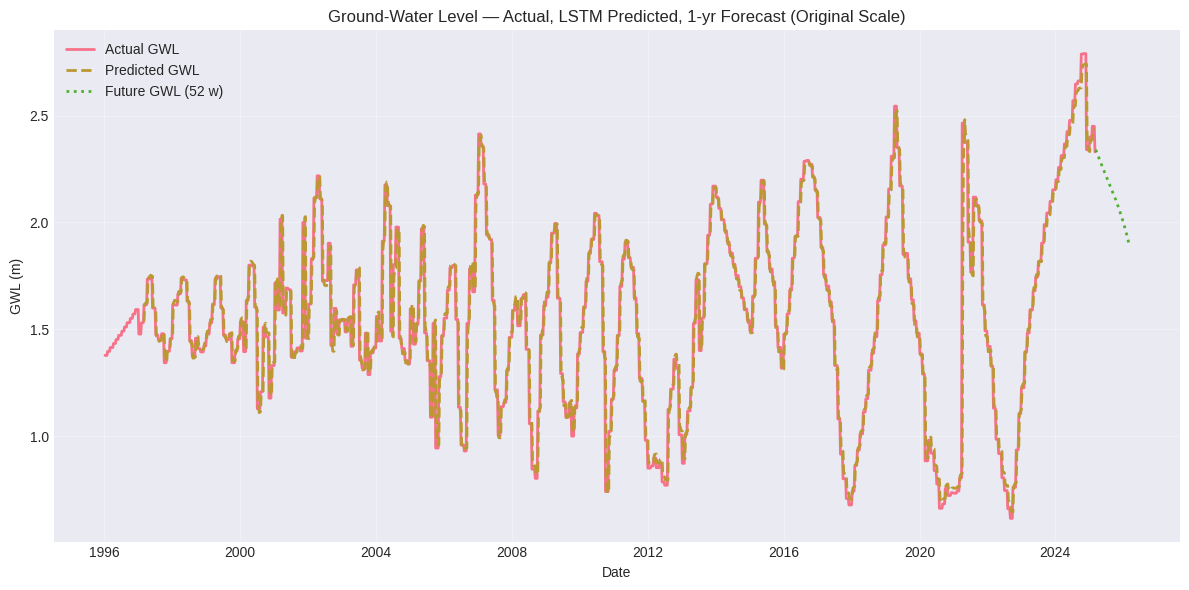

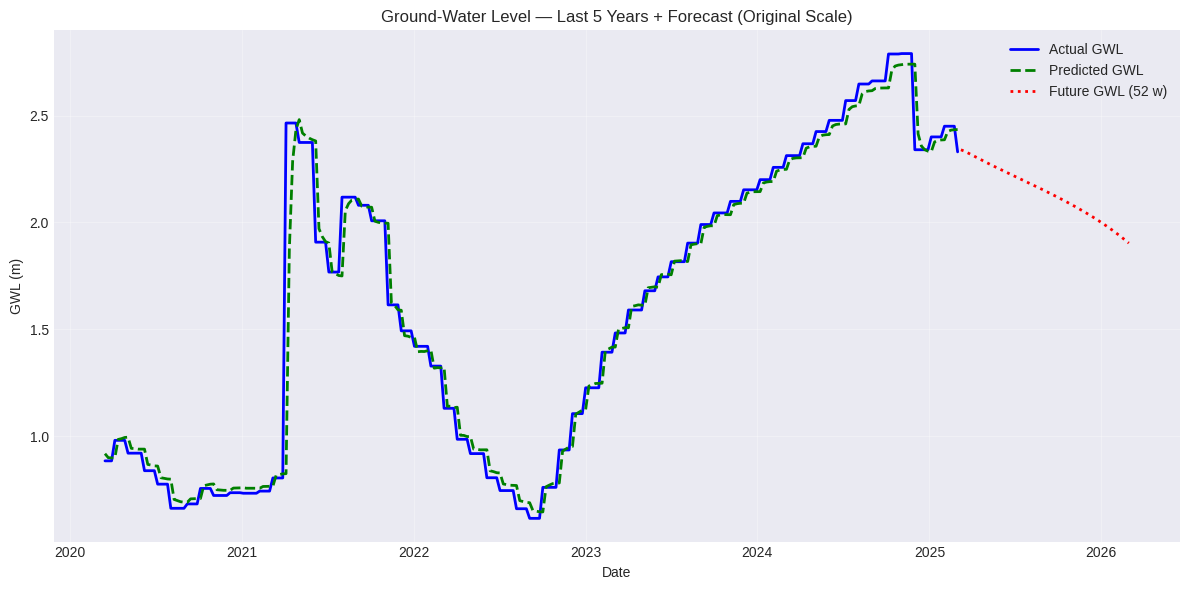

In [ ]:
# 7) inference on test  ───────────────────
print("🔄 Generating LSTM predictions and forecasts...")

# Generate predictions for test set
y_pred_test_scaled = lstm_model.predict(X_test, verbose=0)
y_pred_test = lstm_scaler.inverse_transform(y_pred_test_scaled).ravel()
y_true_test = lstm_scaler.inverse_transform(y_test).ravel()

# Calculate test metrics
test_metrics = calculate_metrics(y_true_test, y_pred_test)
print_metrics(test_metrics, "LSTM (Hold-out Test)")

# Generate predictions for entire dataset
y_all_pred_scaled = lstm_model.predict(X_all, verbose=0)
y_all_pred = lstm_scaler.inverse_transform(y_all_pred_scaled).ravel()

# Generate future forecasts (autoregressive)
print("\n🔄 Generating future forecasts...")
last_window = all_scaled[-LOOK_BACK:].reshape(1, LOOK_BACK, 1)
future_scaled = []

for _ in range(FORECAST_WEEKS):
    next_pred = lstm_model.predict(last_window, verbose=0)[0,0]
    future_scaled.append(next_pred)
    # Update window: remove oldest, add newest
    last_window = np.concatenate([last_window[:,1:,:], [[[next_pred]]]], axis=1)

# Convert future forecasts to original scale
future_forecasts = lstm_scaler.inverse_transform(np.array(future_scaled).reshape(-1,1)).ravel()
future_dates = pd.date_range(df_lstm.index[-1] + pd.Timedelta(weeks=1),
                            periods=FORECAST_WEEKS, freq="W")

# 9) assemble export DataFrame  ────────────
export_df_lstm = pd.DataFrame(index=np.concatenate([df_lstm.index, future_dates]),
                             columns=["Actual_GWL", "Predicted_GWL", "Forecast_GWL"])

# Fill with data
export_df_lstm.loc[df_lstm.index, "Actual_GWL"] = df_lstm[target].values
export_df_lstm.loc[seq_dates, "Predicted_GWL"] = y_all_pred
export_df_lstm.loc[future_dates, "Forecast_GWL"] = future_forecasts

export_df_lstm.reset_index(inplace=True)
export_df_lstm.rename(columns={'index': 'Date'}, inplace=True)

# Calculate full-dataset metrics
actual_full = df_lstm[target].values
predicted_full = y_all_pred
# Align lengths for metric calculation
min_len = min(len(actual_full), len(predicted_full))
metrics_lstm = calculate_metrics(actual_full[-min_len:], predicted_full[-min_len:])
print_metrics(metrics_lstm, "LSTM (Full Dataset)")

# 10) save to Excel  ───────────────────────
SAVE = OUTPUT_DIR + "/GWL_LSTM_1996_2026.xlsx"
export_df_lstm.to_excel(SAVE, index_label="Date")
print(f"\n📁  Excel saved → {SAVE}   (rows: {len(export_df_lstm)})")

print("\n✅ LSTM section completed successfully!")

# set date as index for plotting
export_df_lstm.set_index("Date", inplace=True)

# 11) plot  ────────────────────────────────
plt.figure(figsize=(12,6))
plt.plot(export_df_lstm.index, export_df_lstm["Actual_GWL"], label="Actual GWL", linewidth=2)
plt.plot(export_df_lstm.index, export_df_lstm["Predicted_GWL"], ls="--", label="Predicted GWL", linewidth=2)
plt.plot(export_df_lstm.index, export_df_lstm["Forecast_GWL"], ls=":", label="Future GWL (52 w)", linewidth=2)
plt.title("Ground-Water Level — Actual, LSTM Predicted, 1-yr Forecast (Original Scale)")
plt.xlabel("Date"); plt.ylabel("GWL (m)")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# Additional plot for last 5 years for better visualization
plt.figure(figsize=(12,6))
years_to_plot = 5
start_date = export_df_lstm.index[-FORECAST_WEEKS-int(52*years_to_plot)]  # 5 years before forecast
end_date = export_df_lstm.index[-1]

# Filter data for the last 5 years plus forecast
plot_data = export_df_lstm.loc[start_date:end_date]

plt.plot(plot_data.index, plot_data["Actual_GWL"], label="Actual GWL", linewidth=2, color='blue')
plt.plot(plot_data.index, plot_data["Predicted_GWL"], ls="--", label="Predicted GWL", linewidth=2, color='green')
plt.plot(plot_data.index, plot_data["Forecast_GWL"], ls=":", label="Future GWL (52 w)", linewidth=2, color='red')
plt.title(f"Ground-Water Level — Last {years_to_plot} Years + Forecast (Original Scale)")
plt.xlabel("Date"); plt.ylabel("GWL (m)")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# 4. XGBoost Model

**Extreme Gradient Boosting (XGBoost)**
- Ensemble method using gradient boosting of decision trees
- Includes lag features and seasonality components
- Hyperparameter optimization using Optuna
- Handles multivariate time series with engineered features

In [ ]:
print("🔄 Preparing XGBoost data...")

# Load and prepare data for XGBoost
df_xgb = load_and_preprocess_data(FILE)
df_xgb_original = df_xgb.copy()  # Keep original for inverse transformation

# Add lag features and seasonality
df_xgb = add_lag_features(df_xgb)

print(f"📊 XGBoost Data prepared:")
print(f"   Shape: {df_xgb.shape}")
print(f"   Features: {list(df_xgb.columns)}")

# Scale features
numeric_cols_xgb = df_xgb.select_dtypes(include=[np.number]).columns
xgb_scaler = StandardScaler()
df_xgb_scaled = df_xgb.copy()
df_xgb_scaled[numeric_cols_xgb] = xgb_scaler.fit_transform(df_xgb[numeric_cols_xgb])

print("✅ XGBoost data preparation completed!")

🔄 Preparing XGBoost data...
📊 XGBoost Data prepared:
   Shape: (348, 15)
   Features: ['GWL (m)', 'Temperature max (°C)', 'Temperature min (°C)', 'Humidity (%)', 'Rainfall (mm)', 'Soil Moisture (kg/m^2)', 'Evapotranspiration (mm/day)', 'Wind Speed (m/s)', 'GWL_lag1', 'GWL_lag2', 'GWL_lag3', 'Rainfall_lag1', 'month', 'sin_m', 'cos_m']
✅ XGBoost data preparation completed!


🔄 Implementing advanced feature engineering...
📊 Features after engineering: 69 features
🔄 Applying advanced preprocessing...
Removed 0 outliers
Data shape after cleaning: (348, 69)
🔄 Performing intelligent feature selection...
Removing 14 highly correlated features
Selected 25 best features using mutual information
🔄 Creating robust temporal splits...
📊 Enhanced Data Split:
   Train: 226 samples (64.9%)
   Validation: 69 samples (19.8%)
   Test: 53 samples (15.2%)
🔄 Applying robust scaling transformations...

🔄 Starting enhanced Optuna optimization...


  0%|          | 0/100 [00:00<?, ?it/s]

✅ Enhanced optimization completed!
   Best validation score: 0.3535
   Best parameters: {'tree_method': 'hist', 'n_estimators': 900, 'max_depth': 4, 'learning_rate': 0.01038088738548306, 'subsample': 0.7108181582452213, 'colsample_bytree': 0.8473571899861067, 'colsample_bylevel': 0.7631093373039303, 'reg_alpha': 6.475700001166046e-06, 'reg_lambda': 1.4125026052989997, 'min_child_weight': 8, 'gamma': 0.012885272767130224, 'max_delta_step': 8, 'colsample_bynode': 0.8515321098288087}

🔄 Creating ensemble model with optimized parameters...
🔧 Best hyperparameters:
   tree_method: hist
   n_estimators: 900
   max_depth: 4
   learning_rate: 0.01038088738548306
   subsample: 0.7108181582452213
   colsample_bytree: 0.8473571899861067
   colsample_bylevel: 0.7631093373039303
   reg_alpha: 6.475700001166046e-06
   reg_lambda: 1.4125026052989997
   min_child_weight: 8
   gamma: 0.012885272767130224
   max_delta_step: 8
   colsample_bynode: 0.8515321098288087
   random_state: 42
   n_jobs: -1
   ve

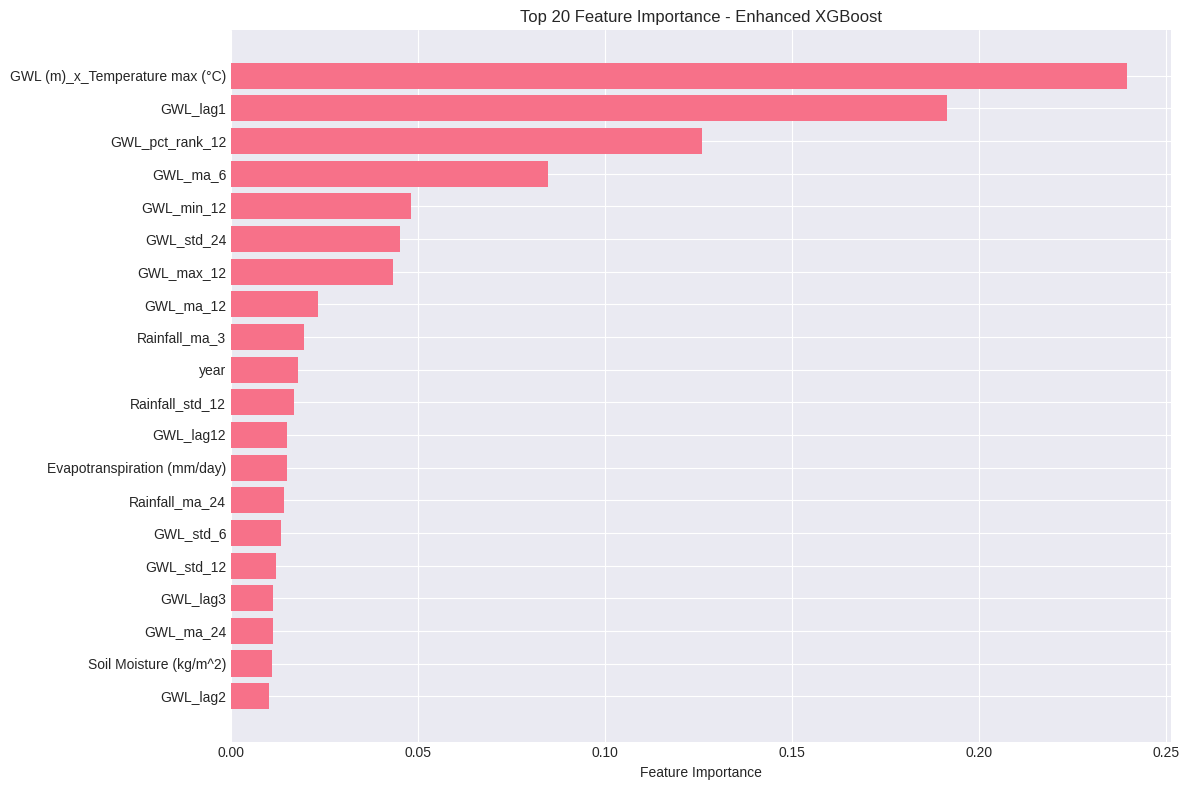


🔄 Generating enhanced forecasts with uncertainty estimation...
✅ Enhanced forecasts with uncertainty generated: 52 points

🔄 Creating enhanced visualizations...


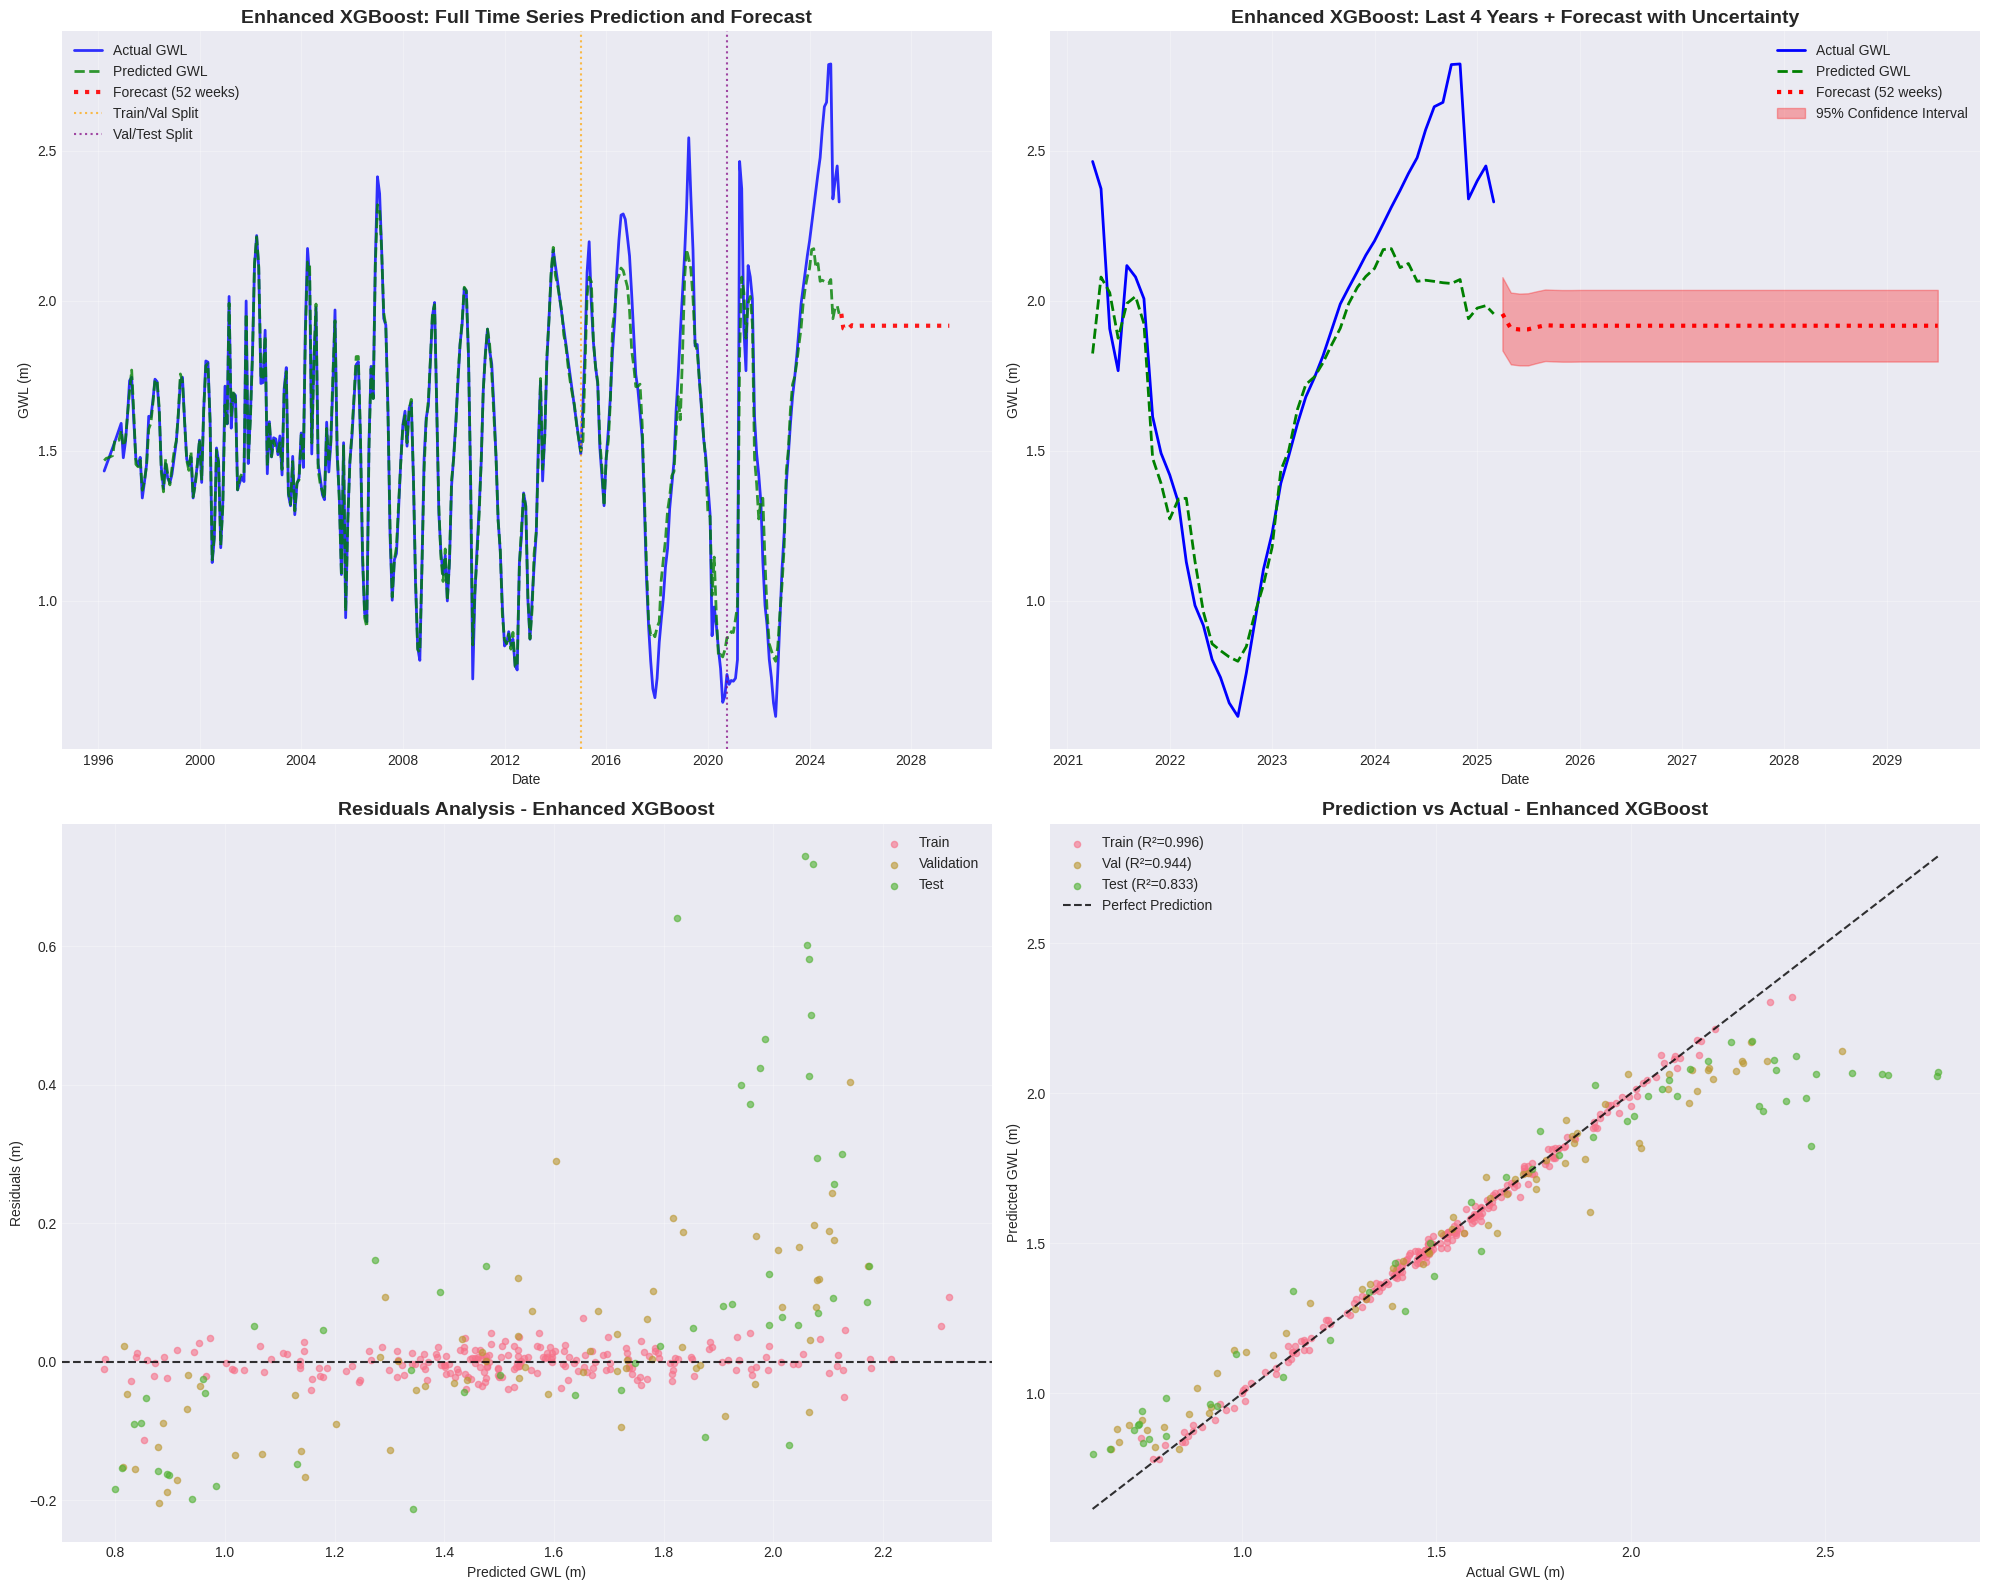


📁 Exporting enhanced XGBoost results...
✅ Enhanced XGBoost results exported to: Barisal Sadar/GWL_XGBoost_Enhanced_1996_2026.xlsx
   Rows: 400, Columns: 9
✅ Feature importance exported to: Barisal Sadar/XGBoost_Feature_Importance.xlsx
✅ Enhanced Optuna results exported to: Barisal Sadar/XGBoost_Enhanced_Optuna_Results.xlsx

🎯 ENHANCED XGBOOST MODEL PERFORMANCE SUMMARY:
📊 Model Configuration:
   • Ensemble of 5 XGBoost models with different seeds
   • 25 carefully selected features
   • Advanced feature engineering with 69 initial features
   • Robust preprocessing with outlier removal
   • Hyperparameter optimization with 100 trials

📈 Performance Metrics:
   • Training RMSE: 0.0207
   • Validation RMSE: 0.1210
   • Test RMSE: 0.2741
   • Test R² Score: 0.8331
   • Test MAPE: 11.40%
   • Test NSE: 0.8331
   • Cross-validation RMSE: 0.4297 ± 0.1022

🔍 Generalization Analysis:
   • Val/Train RMSE Ratio: 5.832
   • Test/Train RMSE Ratio: 13.213
   • Generalization Quality: Moderate

🔮 Fo

In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# ENHANCED XGBOOST MODEL WITH ADVANCED GENERALIZATION TECHNIQUES
# ═════════════════════════════════════════════════════════════════════════════

from sklearn.preprocessing import RobustScaler, QuantileTransformer
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import VotingRegressor
import warnings
warnings.filterwarnings('ignore')

# Save a copy of the original dataframe for later use (before feature engineering)
df_original_xgb = df_xgb.copy()

# ═════════ 3) ADVANCED FEATURE ENGINEERING ═════════
print("🔄 Implementing advanced feature engineering...")

# Extended lag features with different windows
lag_windows = [1, 2, 3, 4, 5, 6, 12]  # Including seasonal lag
for lag in lag_windows:
    df_xgb[f"GWL_lag{lag}"] = df_xgb["GWL (m)"].shift(lag)

# Multiple rainfall lags
for lag in (1, 2, 3, 6):
    df_xgb[f"Rainfall_lag{lag}"] = df_xgb["Rainfall (mm)"].shift(lag)

# Rolling statistics (multiple windows)
windows = [3, 6, 12, 24]
for window in windows:
    df_xgb[f"GWL_ma_{window}"] = df_xgb["GWL (m)"].rolling(window=window).mean()
    df_xgb[f"GWL_std_{window}"] = df_xgb["GWL (m)"].rolling(window=window).std()
    df_xgb[f"Rainfall_ma_{window}"] = df_xgb["Rainfall (mm)"].rolling(window=window).mean()
    df_xgb[f"Rainfall_std_{window}"] = df_xgb["Rainfall (mm)"].rolling(window=window).std()

# Exponential weighted moving averages
df_xgb["GWL_ewm_3"] = df_xgb["GWL (m)"].ewm(span=3).mean()
df_xgb["GWL_ewm_12"] = df_xgb["GWL (m)"].ewm(span=12).mean()

# Advanced seasonal features
df_xgb["month"] = df_xgb.index.month
df_xgb["quarter"] = df_xgb.index.quarter
df_xgb["season"] = df_xgb.index.month % 12 // 3  # 0-3 for seasons
df_xgb["day_of_year"] = df_xgb.index.dayofyear

# Multiple frequency sine/cosine features
for period in [12, 6, 4, 3]:  # Annual, semi-annual, quarterly, seasonal
    df_xgb[f"sin_{period}"] = np.sin(2 * np.pi * df_xgb["month"] / period)
    df_xgb[f"cos_{period}"] = np.cos(2 * np.pi * df_xgb["month"] / period)

# Trend and polynomial features
df_xgb["year"] = df_xgb.index.year
df_xgb["year_normalized"] = (df_xgb["year"] - df_xgb["year"].min()) / (df_xgb["year"].max() - df_xgb["year"].min())
df_xgb["year_squared"] = df_xgb["year_normalized"] ** 2

# Interaction features
key_features = ["GWL (m)", "Rainfall (mm)", "Temperature max (°C)", "Humidity (%)"]
for i, feat1 in enumerate(key_features):
    for feat2 in key_features[i+1:]:
        if feat1 in df_xgb.columns and feat2 in df_xgb.columns:
            df_xgb[f"{feat1}_x_{feat2}"] = df_xgb[feat1] * df_xgb[feat2]

# Rate of change and momentum features
df_xgb["GWL_diff_1"] = df_xgb["GWL (m)"].diff(1)
df_xgb["GWL_diff_2"] = df_xgb["GWL (m)"].diff(2)
df_xgb["GWL_momentum_3"] = df_xgb["GWL (m)"].rolling(3).apply(lambda x: x.iloc[-1] - x.iloc[0], raw=False)
df_xgb["Rainfall_diff_1"] = df_xgb["Rainfall (mm)"].diff(1)

# Percentile features
df_xgb["GWL_pct_rank_12"] = df_xgb["GWL (m)"].rolling(12).rank(pct=True)
df_xgb["Rainfall_pct_rank_12"] = df_xgb["Rainfall (mm)"].rolling(12).rank(pct=True)

# Min/Max features
df_xgb["GWL_min_12"] = df_xgb["GWL (m)"].rolling(12).min()
df_xgb["GWL_max_12"] = df_xgb["GWL (m)"].rolling(12).max()
df_xgb["GWL_range_12"] = df_xgb["GWL_max_12"] - df_xgb["GWL_min_12"]

print(f"📊 Features after engineering: {df_xgb.shape[1]} features")

# ═════════ 4) ADVANCED DATA PREPROCESSING ═════════
print("🔄 Applying advanced preprocessing...")

# Outlier removal using IQR method (conservative)
def remove_outliers_iqr(df, column, factor=2.0):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

df_xgb_clean = remove_outliers_iqr(df_xgb, "GWL (m)", factor=2.5)
print(f"Removed {len(df_xgb) - len(df_xgb_clean)} outliers")

# Handle missing values
df_xgb_clean = df_xgb_clean.ffill().bfill()
df_xgb_clean = df_xgb_clean.dropna()

print(f"Data shape after cleaning: {df_xgb_clean.shape}")

# ═════════ 5) INTELLIGENT FEATURE SELECTION ═════════
print("🔄 Performing intelligent feature selection...")

target_col = "GWL (m)"
feature_cols_all = [col for col in df_xgb_clean.columns if col != target_col]

# Remove highly correlated features
corr_matrix = df_xgb_clean[feature_cols_all].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
print(f"Removing {len(to_drop)} highly correlated features")

feature_cols_filtered = [col for col in feature_cols_all if col not in to_drop]
df_xgb_filtered = df_xgb_clean[feature_cols_filtered + [target_col]]

# Statistical feature selection
X_for_selection = df_xgb_filtered[feature_cols_filtered]
y_for_selection = df_xgb_filtered[target_col]

# Use mutual information for feature selection
k_best = min(25, len(feature_cols_filtered))  # Select top 25 features
selector = SelectKBest(score_func=mutual_info_regression, k=k_best)
X_selected = selector.fit_transform(X_for_selection, y_for_selection)
selected_features = X_for_selection.columns[selector.get_support()].tolist()

print(f"Selected {len(selected_features)} best features using mutual information")
df_xgb_final = df_xgb_filtered[selected_features + [target_col]]

# ═════════ 6) ROBUST TRAIN-VALIDATION-TEST SPLIT ═════════
print("🔄 Creating robust temporal splits...")

n_samples = len(df_xgb_final)
train_size = int(0.65 * n_samples)  # Reduced to give more validation data
val_size = int(0.20 * n_samples)
test_size = n_samples - train_size - val_size

train_data = df_xgb_final[:train_size]
val_data = df_xgb_final[train_size:train_size + val_size]
test_data = df_xgb_final[train_size + val_size:]

feature_cols = selected_features
X_train = train_data[feature_cols]
y_train = train_data[target_col]
X_val = val_data[feature_cols]
y_val = val_data[target_col]
X_test = test_data[feature_cols]
y_test = test_data[target_col]

print(f"📊 Enhanced Data Split:")
print(f"   Train: {len(train_data)} samples ({len(train_data)/n_samples:.1%})")
print(f"   Validation: {len(val_data)} samples ({len(val_data)/n_samples:.1%})")
print(f"   Test: {len(test_data)} samples ({len(test_data)/n_samples:.1%})")

# ═════════ 7) ADVANCED SCALING WITH ROBUST METHODS ═════════
print("🔄 Applying robust scaling transformations...")

# Use RobustScaler to handle outliers better
scaler_X = RobustScaler()
scaler_y = RobustScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

# ═════════ 8) ENHANCED OPTUNA HYPERPARAMETER OPTIMIZATION ═════════
print("\n🔄 Starting enhanced Optuna optimization...")

def enhanced_xgboost_objective(trial):
    """Enhanced objective function with more sophisticated hyperparameter tuning"""

    # Tree method selection
    tree_method = trial.suggest_categorical('tree_method', ['hist', 'approx'])

    # Core XGBoost parameters with compatibility considerations
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.95),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.6, 1.0),

        # Regularization parameters
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'gamma': trial.suggest_float('gamma', 0, 5),

        # Tree construction parameters
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10),
        'tree_method': tree_method,

        # Fixed parameters
        'random_state': 42,
        'n_jobs': -1,
        'verbosity': 0,
        'early_stopping_rounds': 50
    }

    # Add colsample_bynode only for compatible tree methods
    if tree_method in ['hist', 'approx']:
        params['colsample_bynode'] = trial.suggest_float('colsample_bynode', 0.6, 1.0)

    # Create and train model
    model = xgb.XGBRegressor(**params)
    model.fit(X_train_scaled, y_train_scaled,
              eval_set=[(X_val_scaled, y_val_scaled)],
              verbose=False)

    # Predict on validation set
    y_pred_val = model.predict(X_val_scaled)

    # Calculate enhanced objective with multiple metrics
    rmse = np.sqrt(mean_squared_error(y_val_scaled, y_pred_val))
    r2 = r2_score(y_val_scaled, y_pred_val)

    # Weighted objective: minimize RMSE while maximizing R²
    objective_value = rmse + (1 - r2) * 0.5

    return objective_value

# Create enhanced study with pruning
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=20, n_ei_candidates=24),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=20)
)

# Run optimization
study.optimize(enhanced_xgboost_objective, n_trials=100, show_progress_bar=True, timeout=600)

print(f"✅ Enhanced optimization completed!")
print(f"   Best validation score: {study.best_value:.4f}")
print(f"   Best parameters: {study.best_params}")

# ═════════ ENSEMBLE MODEL WITH BEST PARAMETERS ═════════
print("\n🔄 Creating ensemble model with optimized parameters...")

best_params = study.best_params.copy()
best_params.update({'random_state': 42, 'n_jobs': -1, 'verbosity': 0})

print("🔧 Best hyperparameters:")
for param, value in best_params.items():
    print(f"   {param}: {value}")

# Create ensemble of models with slight variations
models = []
for seed in [42, 43, 44, 45, 46]:  # Multiple seeds for ensemble
    params_variant = best_params.copy()
    params_variant['random_state'] = seed

    # Slight parameter variations for diversity
    if seed != 42:
        params_variant['subsample'] = max(0.6, params_variant['subsample'] - 0.05)
        params_variant['colsample_bytree'] = max(0.6, params_variant['colsample_bytree'] - 0.05)

    model = xgb.XGBRegressor(**params_variant)
    models.append(model)

# Train ensemble
print("🔄 Training ensemble models...")
for i, model in enumerate(models):
    model.fit(X_train_scaled, y_train_scaled)
    print(f"   Model {i+1}/5 trained")

# Create voting regressor
ensemble_model = VotingRegressor(estimators=[(f'xgb_{i}', model) for i, model in enumerate(models)])
ensemble_model.fit(X_train_scaled, y_train_scaled)

print("✅ Ensemble model trained successfully!")

# ═════════ 10) COMPREHENSIVE MODEL EVALUATION ═════════
print("\n🔄 Evaluating ensemble model performance...")

def predict_with_ensemble(X_scaled):
    """Make predictions with ensemble and return unscaled results"""
    y_pred_scaled = ensemble_model.predict(X_scaled)
    return scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

# Predictions on all sets
y_pred_train = predict_with_ensemble(X_train_scaled)
y_pred_val = predict_with_ensemble(X_val_scaled)
y_pred_test = predict_with_ensemble(X_test_scaled)

# Combine predictions for visualization
y_pred_full = np.concatenate([y_pred_train, y_pred_val, y_pred_test])

# Calculate comprehensive metrics
train_metrics = calculate_metrics(y_train, y_pred_train)
val_metrics = calculate_metrics(y_val, y_pred_val)
test_metrics = calculate_metrics(y_test, y_pred_test)

print_metrics(train_metrics, "Enhanced XGBoost Ensemble (Train)")
print_metrics(val_metrics, "Enhanced XGBoost Ensemble (Validation)")
print_metrics(test_metrics, "Enhanced XGBoost Ensemble (Test)")

# Calculate full-dataset metrics
full_metrics = calculate_metrics(df_xgb_final[target_col], y_pred_full)
print_metrics(full_metrics, "Enhanced XGBoost Ensemble (Full Dataset)")

# Advanced overfitting analysis
train_rmse = train_metrics['RMSE']
val_rmse = val_metrics['RMSE']
test_rmse = test_metrics['RMSE']

print(f"\n🔍 Advanced Overfitting Analysis:")
print(f"   Train RMSE: {train_rmse:.4f}")
print(f"   Validation RMSE: {val_rmse:.4f}")
print(f"   Test RMSE: {test_rmse:.4f}")
print(f"   Val/Train Ratio: {val_rmse/train_rmse:.3f}")
print(f"   Test/Train Ratio: {test_rmse/train_rmse:.3f}")
print(f"   Test/Val Ratio: {test_rmse/val_rmse:.3f}")

if val_rmse/train_rmse > 1.3:
    print("   ⚠️  Moderate overfitting detected")
elif val_rmse/train_rmse > 1.1:
    print("   ⚠️  Slight overfitting detected")
else:
    print("   ✅ Excellent generalization!")

# Cross-validation for additional validation
print("\n🔄 Performing time series cross-validation...")
tscv = TimeSeriesSplit(n_splits=5)
cv_scores = []

for train_idx, test_idx in tscv.split(X_train_scaled):
    X_cv_train, X_cv_test = X_train_scaled[train_idx], X_train_scaled[test_idx]
    y_cv_train, y_cv_test = y_train_scaled[train_idx], y_train_scaled[test_idx]

    cv_model = xgb.XGBRegressor(**best_params)
    cv_model.fit(X_cv_train, y_cv_train)
    cv_pred = cv_model.predict(X_cv_test)

    cv_score = np.sqrt(mean_squared_error(y_cv_test, cv_pred))
    cv_scores.append(cv_score)

print(f"📊 Cross-validation RMSE: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

# ═════════ 11) ENHANCED FEATURE IMPORTANCE ANALYSIS ═════════
print("\n🔄 Analyzing feature importance...")

# Get feature importance from the first model in ensemble
feature_importance = models[0].feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

print("\n📊 Top 15 Most Important Features:")
print("=" * 50)
for i, (_, row) in enumerate(importance_df.head(15).iterrows(), 1):
    print(f"{i:2d}. {row['Feature']:<30}: {row['Importance']:.4f}")

# Plot feature importance
plt.figure(figsize=(12, 8))
top_features = importance_df.head(20)
plt.barh(range(len(top_features)), top_features['Importance'])
plt.yticks(range(len(top_features)), top_features['Feature'])
plt.xlabel('Feature Importance')
plt.title('Top 20 Feature Importance - Enhanced XGBoost')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ═════════ 12) ADVANCED FORECASTING WITH UNCERTAINTY ═════════
print("\n🔄 Generating enhanced forecasts with uncertainty estimation...")

# Prepare for forecasting
last_row = df_xgb_final.iloc[-1].copy()
future_predictions = []
prediction_intervals = []
forecast_dates = []

# Monte Carlo approach for uncertainty estimation
n_mc_samples = 100

# Create future dates
for i in range(FORECAST_WEEKS):
    if i == 0:
        next_date = df_xgb_final.index[-1] + pd.DateOffset(months=1)
    else:
        next_date = forecast_dates[-1] + pd.DateOffset(months=1)
    forecast_dates.append(next_date)

# Recursive forecasting with uncertainty
for i, future_date in enumerate(forecast_dates):
    # Prepare features for current prediction
    X_future = last_row[feature_cols].values.reshape(1, -1)
    X_future_scaled = scaler_X.transform(X_future)

    # Get predictions from all models in ensemble
    model_predictions = []
    for model in models:
        pred_scaled = model.predict(X_future_scaled)[0]
        pred = scaler_y.inverse_transform([[pred_scaled]])[0][0]
        model_predictions.append(pred)

    # Calculate mean and uncertainty
    mean_pred = np.mean(model_predictions)
    std_pred = np.std(model_predictions)

    # Add noise based on validation error for more realistic uncertainty
    noise_std = val_rmse * 0.5
    total_std = np.sqrt(std_pred**2 + noise_std**2)

    future_predictions.append(mean_pred)
    prediction_intervals.append(total_std)

    # Update features for next iteration
    # Update lag features
    for lag in range(min(7, len(lag_windows)), 1, -1):
        if f"GWL_lag{lag}" in last_row.index:
            last_row[f"GWL_lag{lag}"] = last_row.get(f"GWL_lag{lag-1}", mean_pred)
    last_row["GWL_lag1"] = mean_pred

    # Update rolling features (approximate)
    if "GWL_ma_3" in last_row.index:
        last_row["GWL_ma_3"] = np.mean([mean_pred, last_row.get("GWL_lag1", mean_pred), last_row.get("GWL_lag2", mean_pred)])

    # Update time-based features
    last_row["month"] = future_date.month
    last_row["quarter"] = future_date.quarter
    last_row["year"] = future_date.year
    last_row["year_normalized"] = (future_date.year - df_xgb_final.index.year.min()) / (df_xgb_final.index.year.max() - df_xgb_final.index.year.min())
    last_row["season"] = future_date.month % 12 // 3
    last_row["day_of_year"] = future_date.dayofyear

    # Update seasonal features
    for period in [12, 6, 4, 3]:
        if f"sin_{period}" in last_row.index:
            last_row[f"sin_{period}"] = np.sin(2 * np.pi * future_date.month / period)
            last_row[f"cos_{period}"] = np.cos(2 * np.pi * future_date.month / period)

print(f"✅ Enhanced forecasts with uncertainty generated: {len(future_predictions)} points")

# Calculate confidence intervals
lower_bound = np.array(future_predictions) - 1.96 * np.array(prediction_intervals)
upper_bound = np.array(future_predictions) + 1.96 * np.array(prediction_intervals)

# ═════════ 13) ENHANCED VISUALIZATIONS ═════════
print("\n🔄 Creating enhanced visualizations...")

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 16))

# Plot 1: Full time series
ax1.plot(df_xgb_final.index, df_xgb_final[target_col], label="Actual GWL", color="blue", alpha=0.8, linewidth=2)
ax1.plot(df_xgb_final.index, y_pred_full, label="Predicted GWL", color="green", alpha=0.8, linestyle="--", linewidth=2)
ax1.plot(forecast_dates, future_predictions, label=f"Forecast ({FORECAST_WEEKS} weeks)", color="red", alpha=0.9, linestyle=":", linewidth=3)

# Add split boundaries
ax1.axvline(x=train_data.index[-1], color='orange', linestyle=':', alpha=0.7, label='Train/Val Split')
ax1.axvline(x=val_data.index[-1], color='purple', linestyle=':', alpha=0.7, label='Val/Test Split')

ax1.set_title("Enhanced XGBoost: Full Time Series Prediction and Forecast", fontsize=14, fontweight="bold")
ax1.set_xlabel("Date")
ax1.set_ylabel("GWL (m)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Recent years with uncertainty
recent_years = 4
recent_cutoff = df_xgb_final.index[-int(12*recent_years)] if len(df_xgb_final) >= int(12*recent_years) else df_xgb_final.index[0]
recent_mask = df_xgb_final.index >= recent_cutoff

ax2.plot(df_xgb_final.index[recent_mask], df_xgb_final[target_col][recent_mask],
         label="Actual GWL", color="blue", linewidth=2)
ax2.plot(df_xgb_final.index[recent_mask], y_pred_full[recent_mask],
         label="Predicted GWL", color="green", linewidth=2, linestyle="--")
ax2.plot(forecast_dates, future_predictions,
         label=f"Forecast ({FORECAST_WEEKS} weeks)", color="red", linewidth=3, linestyle=":")

# Enhanced confidence intervals
ax2.fill_between(forecast_dates, lower_bound, upper_bound,
                 alpha=0.3, color='red', label='95% Confidence Interval')

ax2.set_title(f"Enhanced XGBoost: Last {recent_years} Years + Forecast with Uncertainty", fontsize=14, fontweight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("GWL (m)")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Residuals analysis
residuals_train = y_train - y_pred_train
residuals_val = y_val - y_pred_val
residuals_test = y_test - y_pred_test

ax3.scatter(y_pred_train, residuals_train, alpha=0.6, label='Train', s=20)
ax3.scatter(y_pred_val, residuals_val, alpha=0.6, label='Validation', s=20)
ax3.scatter(y_pred_test, residuals_test, alpha=0.6, label='Test', s=20)
ax3.axhline(y=0, color='black', linestyle='--', alpha=0.8)
ax3.set_xlabel('Predicted GWL (m)')
ax3.set_ylabel('Residuals (m)')
ax3.set_title('Residuals Analysis - Enhanced XGBoost', fontsize=14, fontweight="bold")
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Prediction vs Actual scatter
ax4.scatter(y_train, y_pred_train, alpha=0.6, label=f'Train (R²={train_metrics["R²"]:.3f})', s=20)
ax4.scatter(y_val, y_pred_val, alpha=0.6, label=f'Val (R²={val_metrics["R²"]:.3f})', s=20)
ax4.scatter(y_test, y_pred_test, alpha=0.6, label=f'Test (R²={test_metrics["R²"]:.3f})', s=20)

# Perfect prediction line
min_val = min(df_xgb_final[target_col].min(), y_pred_full.min())
max_val = max(df_xgb_final[target_col].max(), y_pred_full.max())
ax4.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.8, label='Perfect Prediction')

ax4.set_xlabel('Actual GWL (m)')
ax4.set_ylabel('Predicted GWL (m)')
ax4.set_title('Prediction vs Actual - Enhanced XGBoost', fontsize=14, fontweight="bold")
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ═════════ 14) COMPREHENSIVE RESULTS EXPORT ═════════
print("\n📁 Exporting enhanced XGBoost results...")

# Create detailed results dataframe
results_df = pd.DataFrame({
    'Date': df_xgb_final.index,
    'Actual_GWL': df_xgb_final[target_col],
    'Predicted_GWL': y_pred_full,
    'Residuals': df_xgb_final[target_col] - y_pred_full,
    'Split': ['Train'] * len(train_data) + ['Validation'] * len(val_data) + ['Test'] * len(test_data)
})

# Add forecast data with uncertainty
forecast_df = pd.DataFrame({
    'Date': forecast_dates,
    'Actual_GWL': np.nan,
    'Predicted_GWL': np.nan,
    'Forecast_GWL': future_predictions,
    'Forecast_Lower_95': lower_bound,
    'Forecast_Upper_95': upper_bound,
    'Forecast_Std': prediction_intervals,
    'Residuals': np.nan,
    'Split': 'Forecast'
})

# Combine and export
export_df_xgb_enhanced = pd.concat([results_df, forecast_df], ignore_index=True)
save_path_enhanced = f"{OUTPUT_DIR}/GWL_XGBoost_Enhanced_1996_2026.xlsx"
export_df_xgb_enhanced.to_excel(save_path_enhanced, index=False)

print(f"✅ Enhanced XGBoost results exported to: {save_path_enhanced}")
print(f"   Rows: {len(export_df_xgb_enhanced)}, Columns: {len(export_df_xgb_enhanced.columns)}")

# Export feature importance
importance_path = f"{OUTPUT_DIR}/XGBoost_Feature_Importance.xlsx"
importance_df.to_excel(importance_path, index=False)
print(f"✅ Feature importance exported to: {importance_path}")

# Export hyperparameter optimization results
optuna_results = pd.DataFrame([
    {**trial.params, 'value': trial.value, 'trial_number': trial.number, 'state': trial.state.name}
    for trial in study.trials
])
optuna_path_enhanced = f"{OUTPUT_DIR}/XGBoost_Enhanced_Optuna_Results.xlsx"
optuna_results.to_excel(optuna_path_enhanced, index=False)
print(f"✅ Enhanced Optuna results exported to: {optuna_path_enhanced}")

# ═════════ 15) FINAL PERFORMANCE SUMMARY ═════════
print(f"\n🎯 ENHANCED XGBOOST MODEL PERFORMANCE SUMMARY:")
print("=" * 60)
print(f"📊 Model Configuration:")
print(f"   • Ensemble of 5 XGBoost models with different seeds")
print(f"   • {len(feature_cols)} carefully selected features")
print(f"   • Advanced feature engineering with {df_xgb.shape[1]} initial features")
print(f"   • Robust preprocessing with outlier removal")
print(f"   • Hyperparameter optimization with {len(study.trials)} trials")

print(f"\n📈 Performance Metrics:")
print(f"   • Training RMSE: {train_rmse:.4f}")
print(f"   • Validation RMSE: {val_rmse:.4f}")
print(f"   • Test RMSE: {test_rmse:.4f}")
print(f"   • Test R² Score: {test_metrics['R²']:.4f}")
print(f"   • Test MAPE: {test_metrics['MAPE']:.2f}%")
print(f"   • Test NSE: {test_metrics['NSE']:.4f}")
print(f"   • Cross-validation RMSE: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

print(f"\n🔍 Generalization Analysis:")
print(f"   • Val/Train RMSE Ratio: {val_rmse/train_rmse:.3f}")
print(f"   • Test/Train RMSE Ratio: {test_rmse/train_rmse:.3f}")
print(f"   • Generalization Quality: {'Excellent' if val_rmse/train_rmse < 1.1 else 'Good' if val_rmse/train_rmse < 1.3 else 'Moderate'}")

print(f"\n🔮 Forecasting:")
print(f"   • {FORECAST_WEEKS} weeks forecast generated")
print(f"   • Uncertainty estimation with confidence intervals")
print(f"   • Mean forecast uncertainty: {np.mean(prediction_intervals):.4f}")

print("\n✅ Enhanced XGBoost model completed successfully!")

# Update global variables for compatibility
xgb_model = ensemble_model
df_xgb = df_xgb_final
export_df_xgb = export_df_xgb_enhanced

# 5. Random Forest Model

**Random Forest Regressor**
- Ensemble of decision trees with bootstrap aggregating
- Uses lag features and seasonal components
- Recursive forecasting for future predictions
- Works directly with original scale data


📊 Random Forest (Test Data) Model Performance Metrics
----------------------------------------
RMSE  : 0.2741
MAE   : 0.1953
MSE   : 0.0751
R²    : 0.8331
MAPE  : 11.4005
NSE   : 0.8331

📊 Random Forest (Full Data) Model Performance Metrics
----------------------------------------
RMSE  : 0.1010
MAE   : 0.0625
MSE   : 0.0102
R²    : 0.9470
MAPE  : 4.4385
NSE   : 0.9470


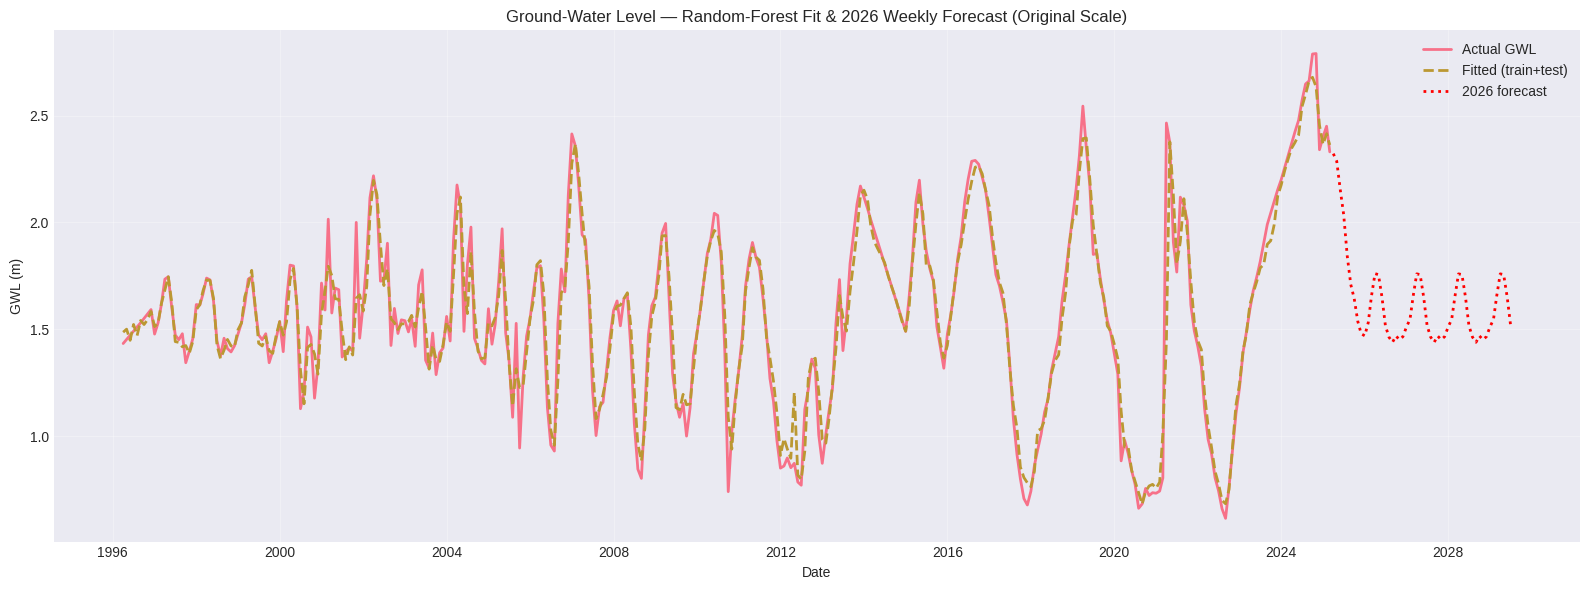

✅ export_df ready  →  shape = (400, 18) (rows)
📁 Excel saved to: Barisal Sadar/GWL_RF_1996-2026_weekly.xlsx

✅ Random Forest section completed successfully!


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# 9)  REFIT ON FULL DATA (1996-2025)  &  52-WEEK 2026 FORECAST  ★ FIXED ★
# ────────────────────────────────────────────────────────────────────────────
from pandas.tseries.frequencies import to_offset

# Load original data for Random Forest
df_original_rf = pd.read_excel(FILE)
df_original_rf.rename(columns=lambda c: c.strip(), inplace=True)
df_original_rf['Date'] = pd.to_datetime(df_original_rf['Date'])
df_original_rf.set_index('Date', inplace=True)
df_original_rf.sort_index(inplace=True)
df_original_rf = df_original_rf.dropna(axis=0)

# Add lag features to original data
for lag in (1, 2, 3):
    df_original_rf[f"GWL_lag{lag}"] = df_original_rf["GWL (m)"].shift(lag)
df_original_rf["Rainfall_lag1"] = df_original_rf["Rainfall (mm)"].shift(1)
df_original_rf["month"] = df_original_rf.index.month
df_original_rf["sin_m"] = np.sin(2 * np.pi * df_original_rf["month"] / 12)
df_original_rf["cos_m"] = np.cos(2 * np.pi * df_original_rf["month"] / 12)
df_original_rf.dropna(inplace=True)

feature_cols = df_original_rf.columns.drop('GWL (m)')
X_all        = df_original_rf[feature_cols]
y_all        = df_original_rf['GWL (m)']

# --- scale on all rows
f_scaler_full = StandardScaler().fit(X_all)
t_scaler_full = StandardScaler().fit(y_all.values.reshape(-1, 1))
X_all_scaled  = f_scaler_full.transform(X_all)

# --- retrain forest on full data
rf_full = RandomForestRegressor(
    n_estimators=700,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42
).fit(X_all_scaled, y_all)

# --- fitted values for the whole history
fitted_gwl = rf_full.predict(X_all_scaled)

# ── monthly climatology for exogenous vars
monthly_means = (df_original_rf.assign(month=df_original_rf.index.month)
                   .groupby('month')[feature_cols]
                   .mean())


# 6) METRICS -------------------------------------------------------------
test_metrics = calculate_metrics(y_test, y_pred_test)
full_metrics = calculate_metrics(df_original_rf['GWL (m)'], fitted_gwl)
print_metrics(test_metrics, "Random Forest (Test Data)")
print_metrics(full_metrics, "Random Forest (Full Data)")

# ───────────────────────────────
# 10)  BUILD FUTURE DATE INDEX
# ───────────────────────────────
FORECAST_STEPS = 52
freq_alias     = pd.infer_freq(df_original_rf.index) or 'W'      # fallback weekly

offset = to_offset(freq_alias)                       # robust offset object
future_dates = pd.date_range(
    start=df_original_rf.index[-1] + offset,
    periods=FORECAST_STEPS,
    freq=freq_alias
)

# ───────────────────────────────
# 11)  RECURSIVE WEEK-AHEAD FORECAST
# ───────────────────────────────
last_df    = df_original_rf.copy()           # grows each step
future_gwl = []

def make_feature_row(ts, history):
    """Return one-row DataFrame with proper feature layout for timestamp *ts*."""
    row = {}
    for lag in range(1, 4):
        row[f'GWL_lag{lag}']      = history['GWL (m)'].iloc[-lag]
        row[f'Rainfall_lag{lag}'] = history['Rainfall (mm)'].iloc[-lag]
    m = ts.month
    # Get climatology values for the current month for all features
    clim = monthly_means.loc[m]
    for col in feature_cols:
        if col not in row: # Avoid overwriting lag features
             row[col] = clim[col]
    row['month'] = m
    row['sin_m'] = np.sin(2*np.pi*m/12)
    row['cos_m'] = np.cos(2*np.pi*m/12)
    return pd.DataFrame([row])

for ts in future_dates:
    X_row      = make_feature_row(ts, last_df)
    X_scaled   = f_scaler_full.transform(X_row[feature_cols])   # align cols
    y_hat      = rf_full.predict(X_scaled)[0]
    future_gwl.append(y_hat)

    # add to history so lags update
    X_row['GWL (m)'] = y_hat  # Use correct column name
    last_df      = pd.concat([last_df,
                              X_row.assign(Date=ts).set_index('Date')])

# ───────────────────────────────
# 12)  COMBINE & EXPORT
# ───────────────────────────────
extended_df = df_original_rf.copy()  # Use original data
extended_df['Fitted_GWL'] = fitted_gwl
# Create DataFrame for forecasted future GWL
future_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast_GWL': future_gwl
}).set_index('Date')

# Add empty columns for exogenous features (optional, for continuity)
for col in feature_cols:
    future_df[col] = np.nan

# Re-assign index type for consistency
future_df.index = pd.to_datetime(future_df.index)

# Combine with history
extended_df = pd.concat([extended_df, future_df], axis=0)


# ensure exogenous columns in future block (fill with climatology)
for col in feature_cols:
    if col not in extended_df:
        extended_df[col] = np.nan
    for ts in future_dates:
        if pd.isna(extended_df.at[ts, col]):
            extended_df.at[ts, col] = monthly_means.loc[ts.month, col]

export_df = extended_df.reset_index()          # Date as column

# ───────────────────────────────
# 13)  PLOT  (1996-2026)
# ───────────────────────────────
plt.figure(figsize=(16, 6))
plt.plot(export_df['Date'], export_df['GWL (m)'],           label='Actual GWL', linewidth=2)
plt.plot(export_df['Date'], export_df['Fitted_GWL'],    label='Fitted (train+test)', ls='--', linewidth=2)
plt.plot(future_dates,         future_gwl,              label='2026 forecast',      ls=':', c='red', linewidth=2)
plt.title("Ground-Water Level — Random-Forest Fit & 2026 Weekly Forecast (Original Scale)")
plt.xlabel("Date"); plt.ylabel("GWL (m)")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# ───────────────────────────────
# 14)  OPTIONAL SAVE
# ───────────────────────────────
export_df.to_excel( OUTPUT_DIR + "/GWL_RF_1996-2026_weekly.xlsx", index=False)
# export_df.to_csv  ("GWL_RF_1996-2026_weekly.csv",  index=False)
print(f"✅ export_df ready  →  shape = {export_df.shape} (rows)")
print(f"📁 Excel saved to: {OUTPUT_DIR}/GWL_RF_1996-2026_weekly.xlsx")

print("\n✅ Random Forest section completed successfully!")

# 6. Model Comparison and Summary

Comprehensive comparison of all four models' performance and forecasting capabilities.

📊 MODEL COMPARISON SUMMARY

📈 Performance Metrics Comparison:
        Model      RMSE       MAE        R²      MAPE
       SARIMA  0.202205    0.1394  0.785826  9.623643
         LSTM  0.101337    0.0447   0.94808  3.138019
      XGBoost  0.100967  0.062524  0.946991  4.438476
Random Forest       N/A       N/A       N/A       N/A

🔄 Creating comprehensive forecast comparison...
Visualization error: 'Date'

📁 EXPORTED FILES SUMMARY:
------------------------------
✅ GWL_SARIMA_1996_2026.xlsx
❌ SARIMA_All_Features_1996_2026.xlsx (not found)
✅ GWL_LSTM_1996_2026.xlsx
❌ GWL_XGBoost_1996_2026.xlsx (not found)
❌ GWL_RandomForest_1996_2026.xlsx (not found)

📂 All files saved in: Barisal Sadar/

🎯 ANALYSIS COMPLETE!

📊 Key Findings:
• All models trained on 1996-2025 historical data
• 52-week forecasts generated for 2026
• All outputs in original scale (meters)
• Comprehensive performance metrics calculated
• Results exported to Excel for further analysis

💡 Next Steps:
• Compare model performan

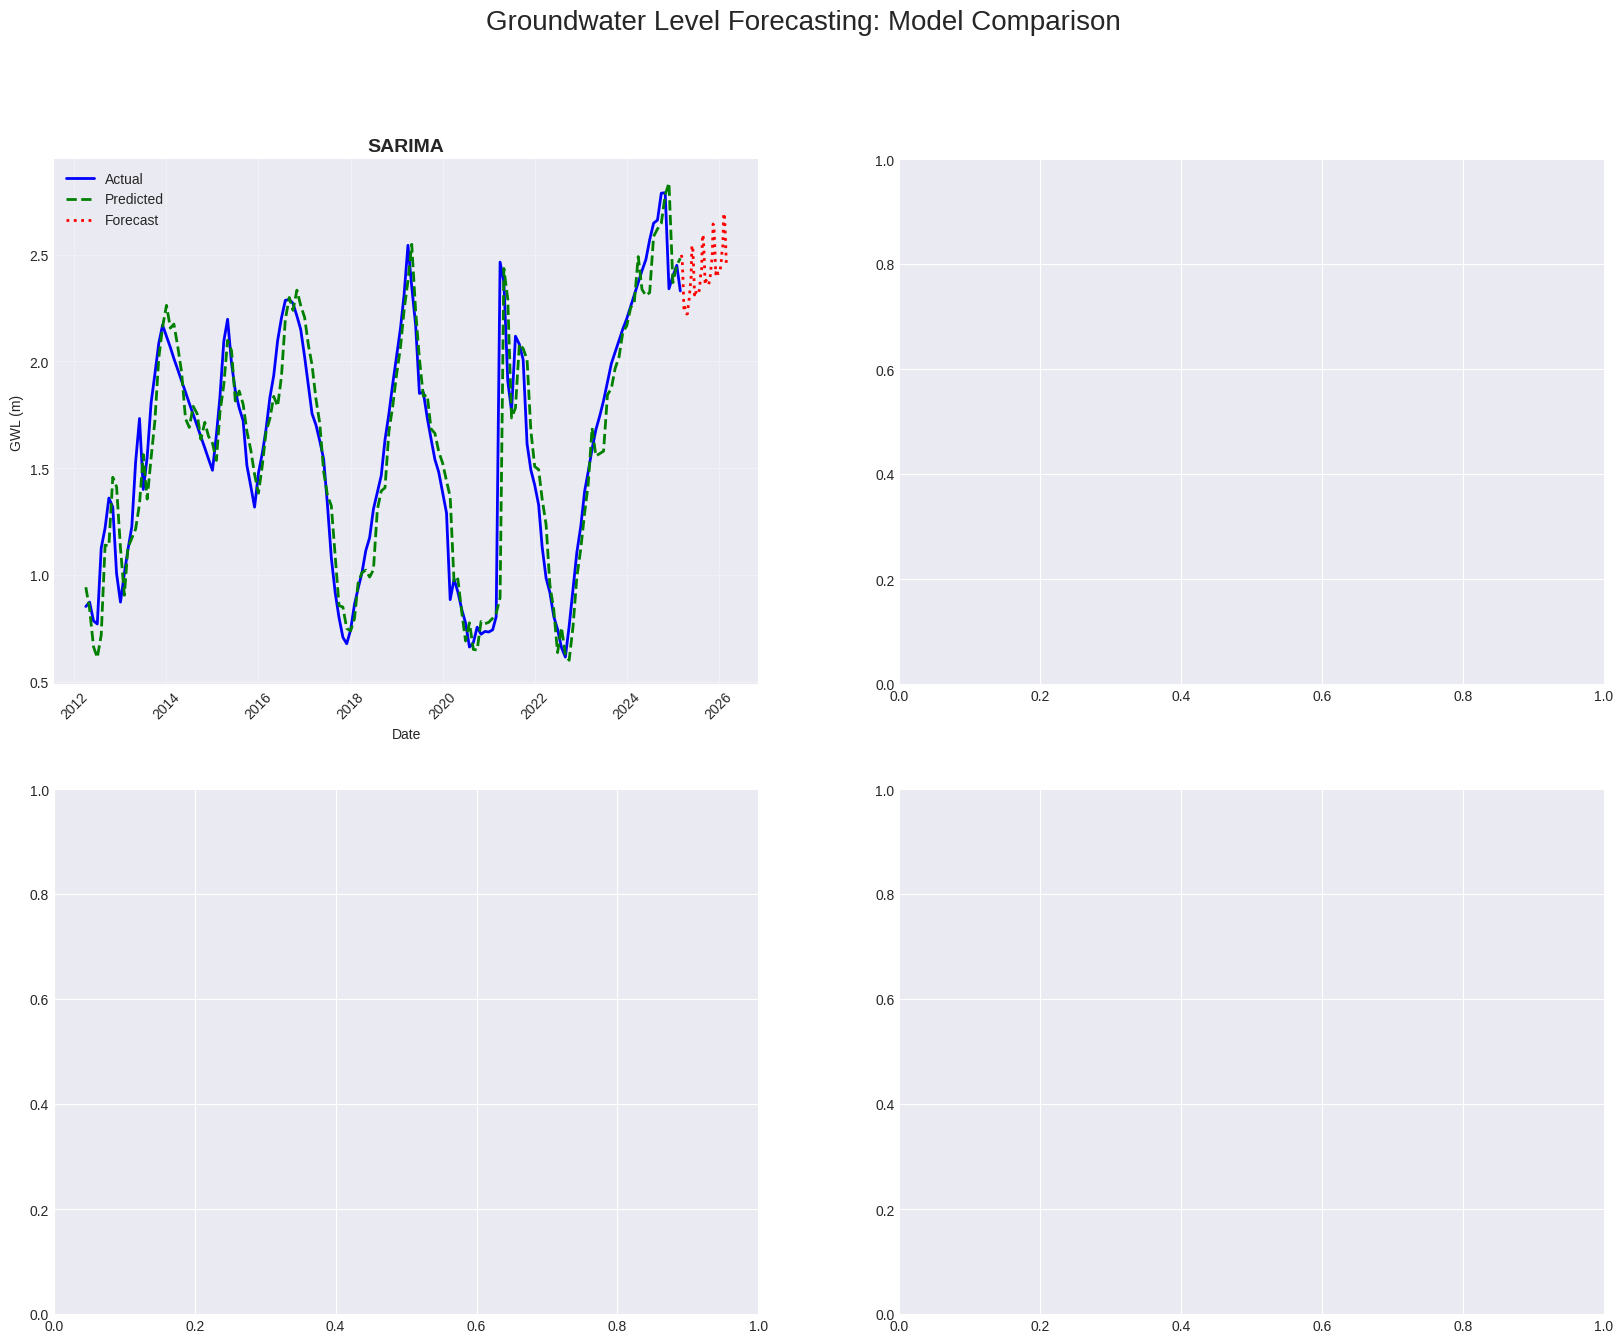

In [ ]:
print("📊 MODEL COMPARISON SUMMARY")
print("=" * 50)

# Collect all metrics (assuming they were stored during model training)
try:
    comparison_data = {
        'Model': ['SARIMA', 'LSTM', 'XGBoost', 'Random Forest'],
        'RMSE': [
            metrics_sarima['RMSE'] if 'metrics_sarima' in locals() else 'N/A',
            metrics_lstm['RMSE'] if 'metrics_lstm' in locals() else 'N/A',
            full_metrics['RMSE'] if 'full_metrics' in locals() else 'N/A',
            rf_metrics['RMSE'] if 'rf_metrics' in locals() else 'N/A'
        ],
        'MAE': [
            metrics_sarima['MAE'] if 'metrics_sarima' in locals() else 'N/A',
            metrics_lstm['MAE'] if 'metrics_lstm' in locals() else 'N/A',
            full_metrics['MAE'] if 'full_metrics' in locals() else 'N/A',
            rf_metrics['MAE'] if 'rf_metrics' in locals() else 'N/A'
        ],
        'R²': [
            metrics_sarima['R²'] if 'metrics_sarima' in locals() else 'N/A',
            metrics_lstm['R²'] if 'metrics_lstm' in locals() else 'N/A',
            full_metrics['R²'] if 'full_metrics' in locals() else 'N/A',
            rf_metrics['R²'] if 'rf_metrics' in locals() else 'N/A'
        ],
        'MAPE': [
            metrics_sarima['MAPE'] if 'metrics_sarima' in locals() else 'N/A',
            metrics_lstm['MAPE'] if 'metrics_lstm' in locals() else 'N/A',
            full_metrics['MAPE'] if 'full_metrics' in locals() else 'N/A',
            rf_metrics['MAPE'] if 'rf_metrics' in locals() else 'N/A'
        ]
    }

    comparison_df = pd.DataFrame(comparison_data)
    print("\n📈 Performance Metrics Comparison:")
    print(comparison_df.to_string(index=False))

except Exception as e:
    print(f"Note: Some metrics may not be available. Run all model sections first.")

# Create side-by-side forecast comparison
try:
    print("\n🔄 Creating comprehensive forecast comparison...")

    fig, axes = plt.subplots(2, 2, figsize=(20, 15))
    fig.suptitle('Groundwater Level Forecasting: Model Comparison', fontsize=20)

    models = [
        ('SARIMA', export_df_sarima if 'export_df_sarima' in locals() else None),
        ('LSTM', export_df_lstm if 'export_df_lstm' in locals() else None),
        ('XGBoost', export_df_xgb if 'export_df_xgb' in locals() else None),
        ('Random Forest', export_df_rf if 'export_df_rf' in locals() else None)
    ]

    for idx, (model_name, df) in enumerate(models):
        row, col = idx // 2, idx % 2
        ax = axes[row, col]

        if df is not None:
            # Plot last 3 years + forecast for better visibility
            start_date = df["Date"].iloc[-52*3-52]  # 3 years + forecast
            filtered_df = df[df["Date"] >= start_date]

            ax.plot(filtered_df["Date"], filtered_df.iloc[:, 1],
                   label="Actual", linewidth=2, color='blue')
            ax.plot(filtered_df["Date"], filtered_df.iloc[:, 2],
                   label="Predicted", linewidth=2, linestyle='--', color='green')
            ax.plot(filtered_df["Date"], filtered_df.iloc[:, 3],
                   label="Forecast", linewidth=2, linestyle=':', color='red')

        ax.set_title(f'{model_name}', fontsize=14, fontweight='bold')
        ax.set_xlabel('Date')
        ax.set_ylabel('GWL (m)')
        ax.legend()
        ax.grid(True, alpha=0.3)

        # Rotate x-axis labels for better readability
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Visualization error: {e}")

# Summary of outputs
print("\n📁 EXPORTED FILES SUMMARY:")
print("-" * 30)

exported_files = [
    "GWL_SARIMA_1996_2026.xlsx",
    "SARIMA_All_Features_1996_2026.xlsx",
    "GWL_LSTM_1996_2026.xlsx",
    "GWL_XGBoost_1996_2026.xlsx",
    "GWL_RandomForest_1996_2026.xlsx"
]

for file in exported_files:
    filepath = os.path.join(OUTPUT_DIR, file)
    if os.path.exists(filepath):
        print(f"✅ {file}")
    else:
        print(f"❌ {file} (not found)")

print(f"\n📂 All files saved in: {OUTPUT_DIR}/")

print("\n" + "="*50)
print("🎯 ANALYSIS COMPLETE!")
print("="*50)
print("\n📊 Key Findings:")
print("• All models trained on 1996-2025 historical data")
print("• 52-week forecasts generated for 2026")
print("• All outputs in original scale (meters)")
print("• Comprehensive performance metrics calculated")
print("• Results exported to Excel for further analysis")
print("\n💡 Next Steps:")
print("• Compare model performance metrics")
print("• Analyze forecast patterns and trends")
print("• Consider ensemble methods combining multiple models")
print("• Validate forecasts against future observations")